# Facility Resource Intelligence: the full analysis

**How to use:** run every cell from top to bottom (Kernel, then Restart and Run All). The four parts pass their results to each other inside the notebook, so no files are exchanged between them.

| Part | Question it answers | What it produces |
|---|---|---|
| 1. Explore | What does the data look like? | Charts |
| 2. Expected vs actual | How much *should* each site use, and who is fair to compare it with? | An expected-vs-actual table |
| 3. Alerts | Where is use far above expected, and why? | `results/alerts_with_explanations.csv`, `results/detection_scorecard.csv` |
| 4. Priority list | Which problems matter most? | `results/priority_list.csv` |

**Inputs:** the raw tables in `data/` and the SQL view results in `sql/results/`. **Only three files are saved**, all in `results/`. Everything else is shown here in the notebook.

All data is synthetic.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
os.makedirs("results", exist_ok=True)
print("Working folder:", os.getcwd())

Working folder: /mnt/user-data/outputs


# Part 1: Exploring the data (EDA)

**Goal:** before building any model, look at the data and learn what "normal" looks like for each site.


**Key terms**
- **kWh**: units of electricity. **kL**: kilolitres of water. **kg**: waste weight.
- **EUI**: kWh per m² per year. It lets different-sized buildings be compared.
- **CDD (cooling degree days)**: how many degrees above 22°C a day was. More CDD means more air-conditioning.
- **Baseload**: electricity used when the building should be idle (night time).
- **DG**: diesel generator. **kWp**: installed solar capacity.

## Load the data
Three tables are read from the CSV files exported from SQL, and the chart style is set.

In [2]:
"""Phase 3: Exploratory Data Analysis. Reads CSV exports of the Phase-2 SQL views, saves charts + tables."""
import pandas as pd, numpy as np, matplotlib
import matplotlib.pyplot as plt
OUT = "results/"
df  = pd.read_csv("sql/results/vw_daily_clean.csv", parse_dates=["date"])
kpi = pd.read_csv("sql/results/vw_site_kpi.csv").set_index("site_id")
wk  = pd.read_csv("sql/results/vw_waste_kpi.csv")
label = dict(zip(kpi.index, kpi.site_name.str.replace("Site ", "").str.replace(" - ", " ")))   # "A Delhi"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
C = {"General shift": "#4C78A8", "Two shifts": "#F58518", "24x7": "#54A24B"}
sites = list(kpi.index)



## Fig 1: EUI + energy mix
**What this does:** draws the cleaned, annualised **EUI** (energy use intensity = kWh per m² per year) for each site, and how each site gets its energy (grid, solar, diesel generator).

**Why:** it is the quickest first look at who uses the most energy and who depends on diesel.

**Careful:** this is *raw*. A call centre or a 24x7 station is expected to use more than a small office, and hot cities use more cooling energy. We adjust for that in Part 2.

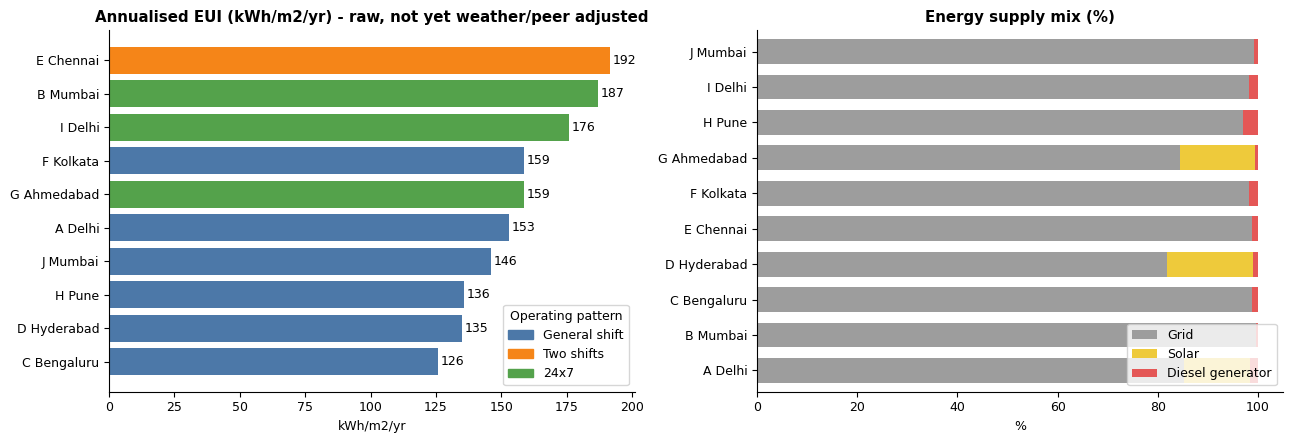

In [3]:
# ---------- Fig 1: EUI + energy mix
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
k = kpi.sort_values("eui_kwh_sqm_yr")
ax[0].barh([label[i] for i in k.index], k.eui_kwh_sqm_yr, color=[C[p] for p in k.operating_pattern])
for y, v in enumerate(k.eui_kwh_sqm_yr): ax[0].text(v + 1, y, f"{v:.0f}", va="center")
ax[0].set_title("Annualised EUI (kWh/m2/yr) - raw, not yet weather/peer adjusted"); ax[0].set_xlabel("kWh/m2/yr")
ax[0].legend(handles=[plt.Rectangle((0,0),1,1,color=c) for c in C.values()], labels=C.keys(), loc="lower right", title="Operating pattern")
mix = df.groupby("site_id")[["grid_kwh_clean","solar_kwh","dg_kwh"]].sum().fillna(0); mix = mix.div(mix.sum(axis=1), axis=0) * 100
mix.index = [label[i] for i in mix.index]
mix.plot.barh(stacked=True, ax=ax[1], color=["#9D9D9D", "#EECA3B", "#E45756"], width=0.7)
ax[1].set_title("Energy supply mix (%)"); ax[1].legend(["Grid", "Solar", "Diesel generator"], loc="lower right"); ax[1].set_xlabel("%")
plt.tight_layout(); plt.show()



## Fig 2: weather sensitivity (weekdays only) + slope table
**What this does:** for each site, plots weekday energy per m² against **cooling degree days (CDD)** and fits a straight line through the dots. Each dot is one weekday.

**Why:** if energy rises with heat, then weather explains part of the consumption, and we must remove that effect before judging a site. The slope of the line says how weather-sensitive the site is.

**What to look for:** most sites have a tight cloud around the line (high R²). Two sites (B Mumbai, C Bengaluru) fit poorly, meaning something other than weather is moving their consumption. That is a clue we follow up in Part 3.

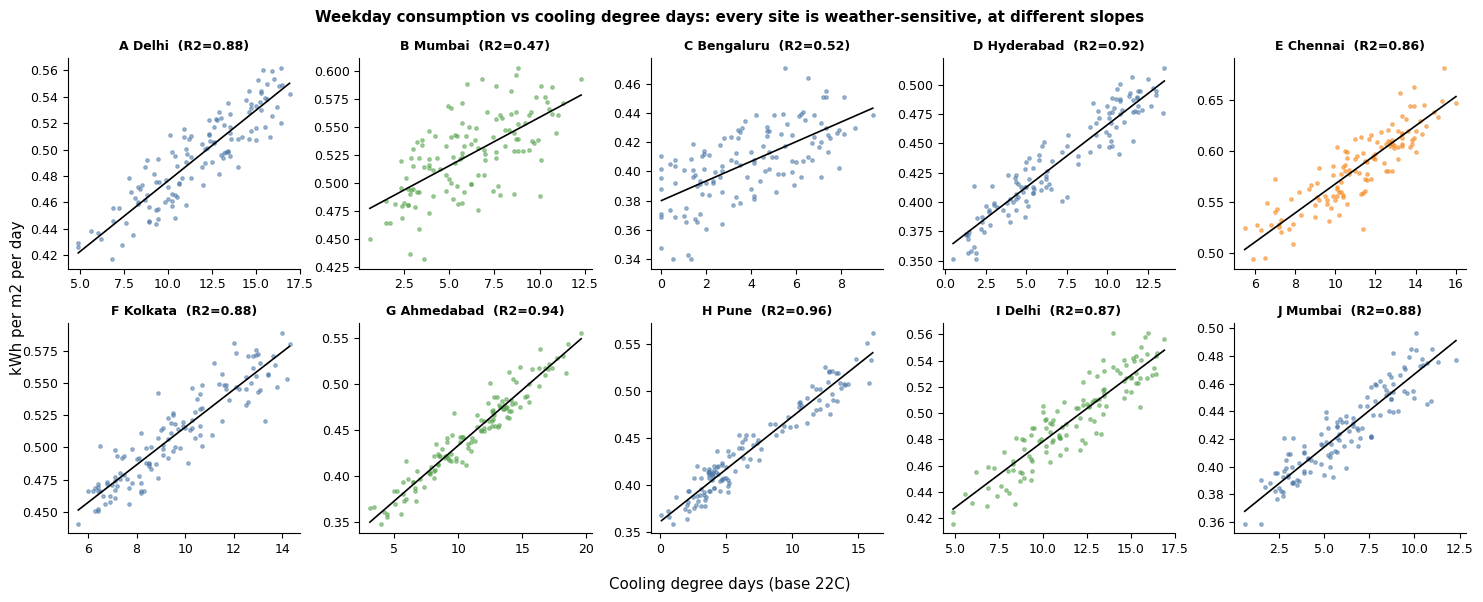

In [4]:
# ---------- Fig 2: weather sensitivity (weekdays only) + slope table
wd = df[df.is_off_day == 0].copy(); wd["kwh_sqm"] = wd.total_consumption_kwh / wd.floor_area_sqm
rows = []
fig, axs = plt.subplots(2, 5, figsize=(15, 6), sharey=False)
for a, s in zip(axs.ravel(), sites):
    d = wd[wd.site_id == s]
    X = np.c_[np.ones(len(d)), d.cdd_base22c, d.headcount / d.floor_area_sqm]
    beta, *_ = np.linalg.lstsq(X, d.kwh_sqm, rcond=None)
    r2 = 1 - ((d.kwh_sqm - X @ beta) ** 2).sum() / ((d.kwh_sqm - d.kwh_sqm.mean()) ** 2).sum()
    rows.append([s, label[s], round(beta[0], 3), round(beta[1], 4), round(beta[2], 2), round(r2, 2)])
    a.scatter(d.cdd_base22c, d.kwh_sqm, s=6, alpha=.5, color=C[kpi.loc[s, "operating_pattern"]])
    xs = np.linspace(d.cdd_base22c.min(), d.cdd_base22c.max(), 20)
    a.plot(xs, beta[0] + beta[1] * xs + beta[2] * (d.headcount / d.floor_area_sqm).mean(), color="k", lw=1.2)
    a.set_title(f"{label[s]}  (R2={r2:.2f})", fontsize=9)
fig.suptitle("Weekday consumption vs cooling degree days: every site is weather-sensitive, at different slopes", fontweight="bold")
fig.supxlabel("Cooling degree days (base 22C)"); fig.supylabel("kWh per m2 per day"); plt.tight_layout(); plt.show()
sens = pd.DataFrame(rows, columns=["site_id", "site", "base_kwh_sqm_day", "kwh_sqm_per_cdd", "kwh_sqm_per_head_density", "r2"])



## Fig 3: weekday vs weekend behaviour
**What this does:** compares energy use on weekends/holidays with weekdays, next to how many people were in the building.

**Why:** a building should use much less when people are away. If energy stays high while people are gone, equipment is running unnecessarily.

**What to look for:** general-shift offices should be near 50%. One site (J Mumbai) sits far above that.

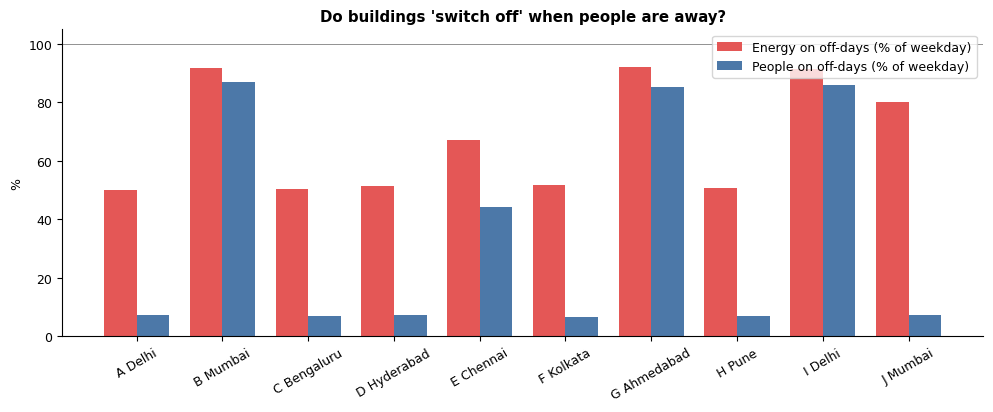

In [5]:
# ---------- Fig 3: weekday vs weekend behaviour
g = df.groupby(["site_id", "is_off_day"]).agg(kwh=("total_consumption_kwh", "mean"), hc=("headcount", "mean")).unstack()
ratio = pd.DataFrame({"energy_offday_ratio": g[("kwh", 1)] / g[("kwh", 0)], "headcount_offday_ratio": g[("hc", 1)] / g[("hc", 0)]})
ratio["gap"] = ratio.energy_offday_ratio - ratio.headcount_offday_ratio
fig, ax = plt.subplots(figsize=(10, 4.2)); x = np.arange(len(sites)); w_ = .38
ax.bar(x - w_/2, ratio.energy_offday_ratio * 100, w_, label="Energy on off-days (% of weekday)", color="#E45756")
ax.bar(x + w_/2, ratio.headcount_offday_ratio * 100, w_, label="People on off-days (% of weekday)", color="#4C78A8")
ax.set_xticks(x); ax.set_xticklabels([label[s] for s in sites], rotation=30); ax.axhline(100, color="grey", lw=.6)
ax.set_title("Do buildings 'switch off' when people are away?"); ax.legend(); ax.set_ylabel("%")
plt.tight_layout(); plt.show()



## Fig 4: night baseload over time (weekly)
**What this does:** plots the weekly average of night-time (12am to 5am) electricity use for every site.

**Why:** at night a building should be nearly idle, so this is the cleanest view of wasted energy ("baseload").

**What to look for:** a flat line is healthy. A sudden jump means something was switched on and left running. In our data C Bengaluru jumps in early July (roughly 259 to 391 kWh).

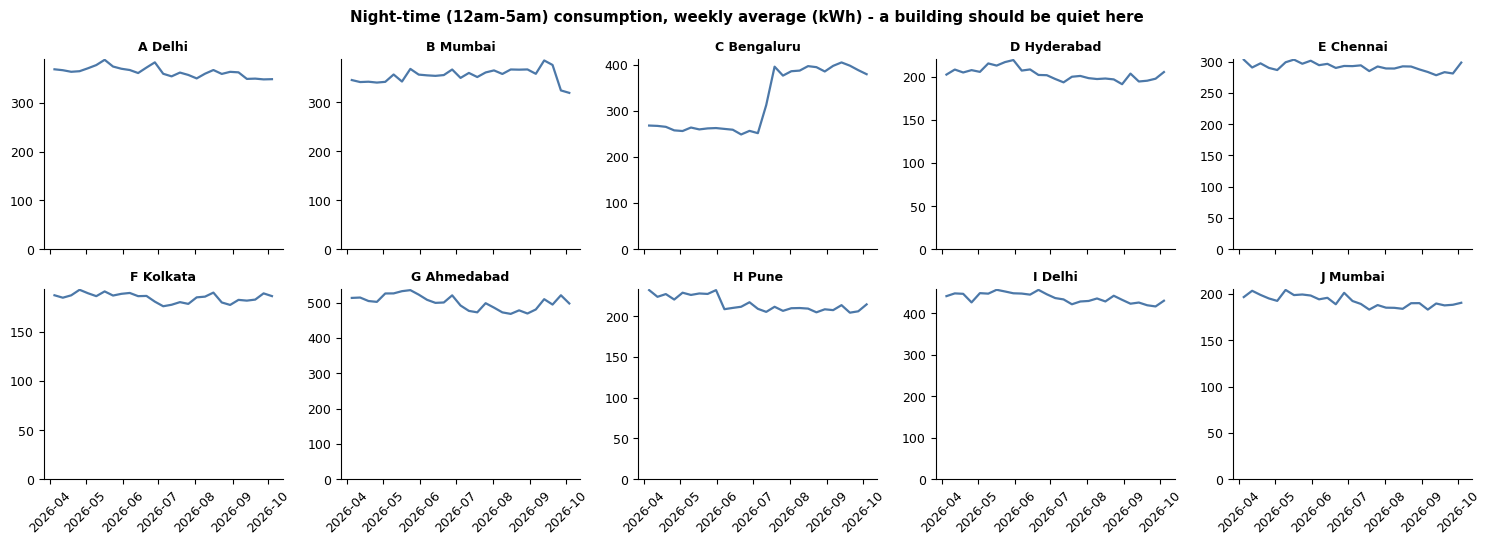

In [6]:
# ---------- Fig 4: night baseload over time (weekly)
wkly = df.set_index("date").groupby("site_id").night_baseload_kwh.resample("W").mean().reset_index()
fig, axs = plt.subplots(2, 5, figsize=(15, 5.5), sharex=True)
for a, s in zip(axs.ravel(), sites):
    d = wkly[wkly.site_id == s]; a.plot(d.date, d.night_baseload_kwh, color="#4C78A8", lw=1.6); a.set_title(label[s], fontsize=9)
    a.tick_params(axis="x", rotation=45); a.set_ylim(0, None)
fig.suptitle("Night-time (12am-5am) consumption, weekly average (kWh) - a building should be quiet here", fontweight="bold")
plt.tight_layout(); plt.show()



## Fig 5: DG vs outages  +  solar yield
**What this does:** two checks. Left: generator running hours against grid outage hours. Right: solar output per kW installed, week by week.

**Why:** a generator should only run when the grid is off (points should sit near the dashed line), and solar sites in similar weather should produce similar output per kW.

**What to look for:** H Pune's generator ran about 121 hours against only about 30 outage hours. Solar sites all fall in the monsoon, but A Delhi drops lower than the other two in August.

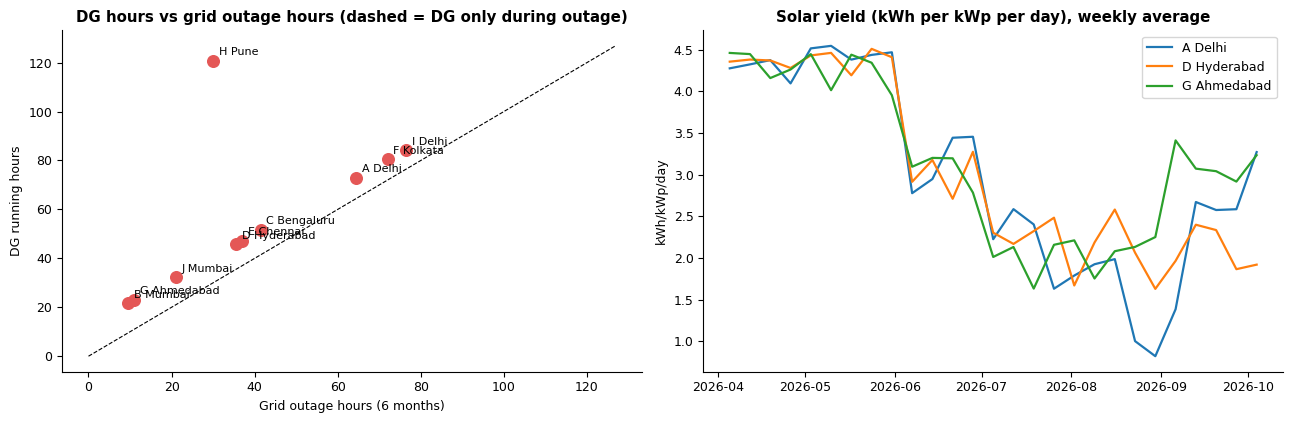

In [7]:
# ---------- Fig 5: DG vs outages  +  solar yield
m = df.groupby("site_id").agg(dg=("dg_runtime_hrs", "sum"), outage=("grid_outage_hrs", "sum")); m["lbl"] = [label[i] for i in m.index]
sol = df[df.solar_capacity_kwp > 0].copy(); sol["yield"] = sol.solar_kwh / sol.solar_capacity_kwp
sw = sol.set_index("date").groupby("site_id")["yield"].resample("W").mean().reset_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].scatter(m.outage, m.dg, s=70, color="#E45756"); lim = max(m.dg.max(), m.outage.max()) * 1.05; ax[0].plot([0, lim], [0, lim], "k--", lw=.8)
for _, r in m.iterrows(): ax[0].annotate(r.lbl, (r.outage, r.dg), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax[0].set_xlabel("Grid outage hours (6 months)"); ax[0].set_ylabel("DG running hours"); ax[0].set_title("DG hours vs grid outage hours (dashed = DG only during outage)")
for s, d in sw.groupby("site_id"): ax[1].plot(d.date, d["yield"], label=label[s], lw=1.6)
ax[1].set_title("Solar yield (kWh per kWp per day), weekly average"); ax[1].legend(); ax[1].set_ylabel("kWh/kWp/day")
plt.tight_layout(); plt.show()



## Fig 6: water per head + waste
**What this does:** three panels: water per person per day (weekly), recycling rate by month, and wet/food waste per person per month.

**Why:** dividing by headcount removes the effect of a busy or quiet week, so a real change stands out.

**What to look for:** F Kolkata's water per head jumps in August. E Chennai recycles much less than the other waste-tracked sites and has a wet-waste spike in August.

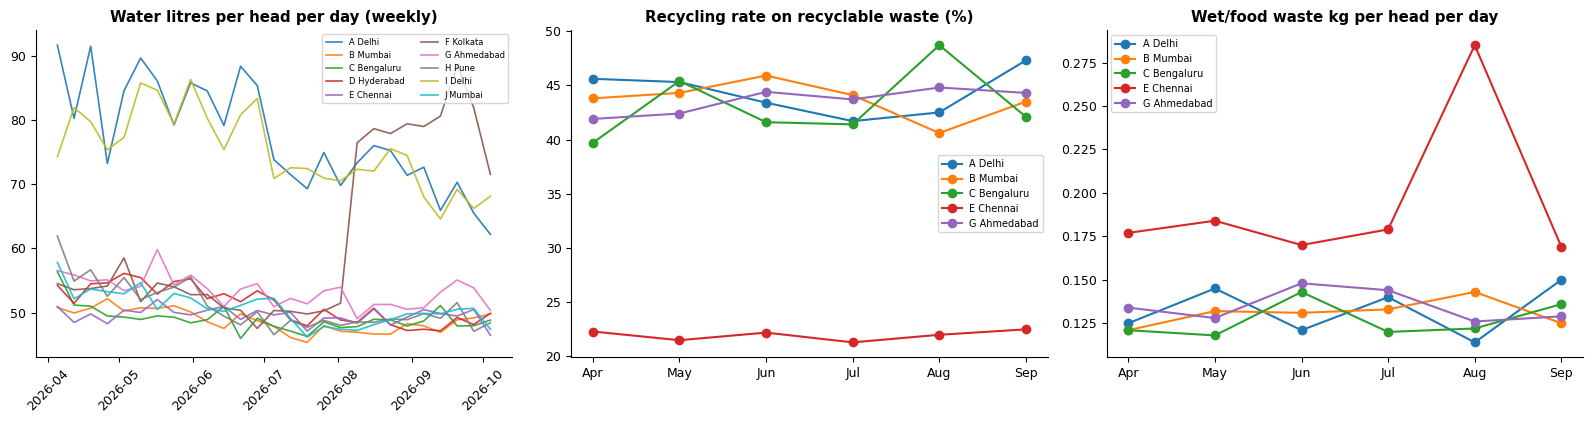

In [8]:
# ---------- Fig 6: water per head + waste
_w = df.groupby(["site_id", pd.Grouper(key="date", freq="W")]).agg(wkl=("water_kl", "sum"), hc=("headcount", "sum")).reset_index()
_w["l_head"] = _w.wkl * 1000 / _w.hc; ww = _w[["site_id", "date", "l_head"]]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for s, d in ww.groupby("site_id"): ax[0].plot(d.date, d.l_head, lw=1.2, label=label[s], alpha=.9)
ax[0].set_title("Water litres per head per day (weekly)"); ax[0].legend(fontsize=6, ncol=2); ax[0].tick_params(axis="x", rotation=45)
p = wk.pivot(index="site_id", columns="month_id", values="recycling_rate_pct"); p.index = [label[i] for i in p.index]
for s in p.index: ax[1].plot(range(4, 10), p.loc[s], marker="o", label=s)
ax[1].set_xticks(range(4, 10)); ax[1].set_xticklabels(["Apr","May","Jun","Jul","Aug","Sep"]); ax[1].set_title("Recycling rate on recyclable waste (%)"); ax[1].legend(fontsize=7)
q = wk.pivot(index="site_id", columns="month_id", values="wet_waste_kg_per_head_day"); q.index = [label[i] for i in q.index]
for s in q.index: ax[2].plot(range(4, 10), q.loc[s], marker="o", label=s)
ax[2].set_xticks(range(4, 10)); ax[2].set_xticklabels(["Apr","May","Jun","Jul","Aug","Sep"]); ax[2].set_title("Wet/food waste kg per head per day"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()



## printed numbers for the write-up
**What this does:** prints the exact numbers behind the charts (night baseload before and after, solar yield by month, water per head by month, recycling rates).

**Why:** charts show the story and these numbers let you quote it with evidence in your write-up.

In [9]:
# ---------- printed numbers for the write-up
pd.set_option("display.width", 200)
print(sens); print(ratio.round(2).assign(site=[label[i] for i in ratio.index]))
print(m.assign(excess=(m.dg - m.outage).round(0)).sort_values("excess", ascending=False).head(4))
for s in ["S03"]:
    d = df[df.site_id == s].copy(); d["pre"] = d.date < "2026-07-10"; print(d.groupby("pre").night_baseload_kwh.mean().round(0).to_dict())
sy = sol.assign(per=lambda x: x.date.dt.to_period("M")).groupby(["site_id", "per"])["yield"].mean().unstack().round(2); print(sy)
ph = df.assign(per=df.date.dt.month).groupby(["site_id", "per"]).apply(lambda x: 1000 * x.water_kl.sum() / x.headcount.sum()).unstack().round(0); print(ph.loc[["S06", "S01", "S09"]])
print(wk.groupby("site_id").recycling_rate_pct.mean().round(0).to_dict())
print(df.groupby("site_id").apply(lambda x: x.groupby("is_off_day").night_baseload_kwh.mean().round(0).to_dict()).loc[["S10","S01"]])
print("corr kwh_sqm vs cdd (weekday) overall:", round(wd.kwh_sqm.corr(wd.cdd_base22c), 2))


  site_id         site  base_kwh_sqm_day  kwh_sqm_per_cdd  kwh_sqm_per_head_density    r2
0     S01      A Delhi             0.267           0.0107                      1.60  0.88
1     S02     B Mumbai             0.391           0.0086                      1.39  0.47
2     S03  C Bengaluru             0.284           0.0067                      1.59  0.52
3     S04  D Hyderabad             0.274           0.0107                      1.54  0.92
4     S05    E Chennai             0.303           0.0143                      1.60  0.86
5     S06    F Kolkata             0.289           0.0146                      1.54  0.88
6     S07  G Ahmedabad             0.263           0.0121                      1.35  0.94
7     S08       H Pune             0.273           0.0112                      1.52  0.96
8     S09      I Delhi             0.308           0.0101                      1.34  0.87
9     S10     J Mumbai             0.279           0.0105                      1.50  0.88
         e

## Summary
- **Done:** looked at energy, water, diesel, solar and waste patterns for all 10 sites.
- **Found (first look only):** weather drives energy use; a few sites behave oddly (C, B, H, J, A, F, E).
- **Next:** Part 2 removes the effect of weather and building type so sites can be compared fairly.

# Part 2: Peer groups and expected-vs-actual baselines

**Goal:** make comparisons *fair*. We (1) group sites that operate alike and (2) work out how much energy each site **should** have used given weather, people present and day type. The difference between actual and expected is the unexplained excess.



## Load the data

In [10]:
"""
PHASE 4: Peer grouping (domain rule: operating hours)     PHASE 5: Expected-vs-actual baseline (per-site regression)
Reads the SQL view results and the raw tables
"""
import pandas as pd, numpy as np, matplotlib
import matplotlib.pyplot as plt

OUT = "results/"
df = pd.read_csv("sql/results/vw_daily_clean.csv", parse_dates=["date"])
site = pd.read_csv("data/dim_site.csv").set_index("site_id")
lab = {i: site.loc[i, "site_name"].replace("Site ", "").replace(" - ", " ") for i in site.index}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})



## Phase 4: Peer groups
**What we do:** put sites into two groups by **operating hours**: *General shift* (6 sites) and *Extended hours* (24x7 and two-shift, 4 sites).

**Why:** a 24x7 cargo hub will always use more than a 9-to-6 office, so comparing them would be unfair. Operating hours are the biggest reason sites differ when people are away, and the data supports it: general-shift sites use about half their weekday energy at weekends, 24x7 sites about 90% (see the chart further down).

**Limitation to state honestly:** groups of 4 and 6 are small. A larger portfolio would allow finer groups.

In [11]:
# =====================================================================
# PHASE 4 - PEER GROUPING
# A building should only be compared with buildings that operate like it. Operating hours are the biggest driver of
# how much energy a building uses when people are away, so peers are grouped by operating pattern.
# (The two-shift site has no like-for-like partner, so it joins the 24x7 sites as "Extended hours".)
# =====================================================================
site["peer_group"] = np.where(site.operating_pattern.isin(["24x7", "Two shifts"]), "Extended hours", "General shift")
print(site.groupby("peer_group").apply(lambda g: ", ".join(lab[i] for i in g.index)).to_string())



peer_group
Extended hours            B Mumbai, E Chennai, G Ahmedabad, I Delhi
General shift     A Delhi, C Bengaluru, D Hyderabad, F Kolkata, ...


## Phase 5: Expected vs actual
**The idea in one line:** learn each site's normal behaviour from April to June, then predict what July to September *should* look like. Anything the prediction cannot explain is suspicious.

**The model:** for every site, a straight-line formula
`expected kWh = a + b×CDD + c×headcount + d×off-day + e×(CDD × off-day)`
"Fitting" means finding a to e so the formula matches April to June as closely as possible (ordinary least squares, `np.linalg.lstsq`). This is regression, a transparent statistical model: you can read exactly how much each factor contributes.

**What we predict:** total consumption (grid + solar + diesel). That is the building's real demand, so switching between solar and generator does not distort it.

**Fair testing:** the model never sees July to September while learning. Days with bad or filled-in readings are left out of training.

In [12]:
# =====================================================================
# PHASE 5 - EXPECTED vs ACTUAL
# Target = total consumption (grid + solar + DG) = building demand, so solar/DG switching does not distort it.
# Per-site linear regression on: cooling degree days, headcount, off-day flag, CDD x off-day.
# Trained on Apr-Jun (clean days only), tested on Jul-Sep which the model has never seen.
# =====================================================================
df = df.merge(site[["peer_group"]], left_on="site_id", right_index=True)
X = lambda d: np.c_[np.ones(len(d)), d.cdd_base22c, d.headcount, d.is_off_day, d.cdd_base22c * d.is_off_day]
coefs, rows = {}, []
df["expected_kwh"] = np.nan
for s, d in df.groupby("site_id"):
    tr = d[(d.date < "2026-07-01") & (d.dq_flag == "OK")]; te = d[d.date >= "2026-07-01"]
    b, *_ = np.linalg.lstsq(X(tr), tr.total_consumption_kwh, rcond=None); coefs[s] = b
    df.loc[d.index, "expected_kwh"] = X(d) @ b
    r_tr = tr.total_consumption_kwh - X(tr) @ b
    r2 = 1 - (r_tr ** 2).sum() / ((tr.total_consumption_kwh - tr.total_consumption_kwh.mean()) ** 2).sum()
    mape = (abs(te.total_consumption_kwh - X(te) @ b) / te.total_consumption_kwh).median() * 100
    rows.append(dict(site_id=s, site=lab[s], train_r2=round(r2, 3), train_resid_sd_kwh=round(r_tr.std(), 1), test_median_abs_pct_err=round(mape, 1)))
M = pd.DataFrame(rows).set_index("site_id")
print("\nBASELINE MODEL QUALITY (test = Jul-Sep, never seen in training):\n", M.to_string())




BASELINE MODEL QUALITY (test = Jul-Sep, never seen in training):
                 site  train_r2  train_resid_sd_kwh  test_median_abs_pct_err
site_id                                                                    
S01          A Delhi     0.992                71.0                      2.3
S02         B Mumbai     0.655                91.0                      5.5
S03      C Bengaluru     0.992                45.0                      9.1
S04      D Hyderabad     0.990                41.4                      2.2
S05        E Chennai     0.981                63.1                      1.7
S06        F Kolkata     0.989                40.7                      1.8
S07      G Ahmedabad     0.899                80.3                      1.9
S08           H Pune     0.993                38.5                      1.9
S09          I Delhi     0.849                67.4                      1.9
S10         J Mumbai     0.944                37.6                      2.1


**How to read the quality table:** `train_r2` close to 1 means the formula explains the training period well. `test_median_abs_pct_err` is the typical error on unseen months (about 2% for most sites). Two sites are worse (B Mumbai and C Bengaluru) for a reason we discover next.

## Residuals: actual minus expected
**What we do:** for every day, `excess = actual − expected`. We also express it as a percentage, a z-score (how big compared with the site's normal wobble), and a rupee value using the site's electricity tariff. Then we total it for July to September.

**Reading the result:** a positive number means the site used more than the model expected.

In [13]:
df["excess_kwh"] = df.total_consumption_kwh - df.expected_kwh
df["excess_pct"] = df.excess_kwh / df.expected_kwh * 100
df["excess_z"] = df.excess_kwh / df.site_id.map(M.train_resid_sd_kwh)
df["excess_inr"] = df.excess_kwh * df.grid_tariff_inr_per_kwh
daily_expected = df[["site_id", "date", "is_off_day", "headcount", "cdd_base22c", "total_consumption_kwh", "expected_kwh", "excess_kwh", "excess_pct", "excess_z", "excess_inr", "peer_group"]] \
    .round(2)

t = df[df.date >= "2026-07-01"]
mon = t.groupby(["site_id", "month_num"]).agg(actual=("total_consumption_kwh", "sum"), expected=("expected_kwh", "sum"), excess_kwh=("excess_kwh", "sum")).reset_index()
mon["excess_pct"] = mon.excess_kwh / mon.expected * 100
S = t.groupby("site_id").agg(actual_kwh=("total_consumption_kwh", "sum"), expected_kwh=("expected_kwh", "sum"), excess_kwh=("excess_kwh", "sum"), excess_inr=("excess_inr", "sum"))
S["excess_pct"] = S.excess_kwh / S.expected_kwh * 100; S["site"] = [lab[i] for i in S.index]
S = S.sort_values("excess_pct", ascending=False).round(1)
print("\nSITE EXCESS vs OWN BASELINE (Jul-Sep):\n", S.to_string()); print(mon.pivot(index="site_id", columns="month_num", values="excess_pct").round(1))




SITE EXCESS vs OWN BASELINE (Jul-Sep):
          actual_kwh  expected_kwh  excess_kwh  excess_inr  excess_pct         site
site_id                                                                           
S03        166328.5      152276.3     14052.2    118038.3         9.2  C Bengaluru
S02        192726.9      184550.7      8176.2     83397.6         4.4     B Mumbai
S07        266907.8      264251.2      2656.6     20987.3         1.0  G Ahmedabad
S09        236914.3      236154.2       760.1      6764.6         0.3      I Delhi
S01        239692.4      239332.8       359.6      3200.8         0.2      A Delhi
S04        119908.4      120258.8      -350.3     -2837.6        -0.3  D Hyderabad
S05        223724.7      225179.2     -1454.5    -11636.2        -0.6    E Chennai
S06        123597.4      124514.7      -917.3     -8072.0        -0.7    F Kolkata
S08        125799.0      126746.8      -947.8     -8909.5        -0.7       H Pune
S10        125364.5      126676.2     -1311.7 

## Peer comparison (catches problems that were *always* there)
**Why we need it:** a site's own baseline only detects things that *changed*. If a problem existed from day one (like J Mumbai not switching off at weekends), the model treats it as normal.

**What we do:** use each site's formula to ask "what would your intensity be on a standard weekday and a standard off-day, at the same weather?" and compare with the median of its peer group (100 = typical).

In [14]:
# ---------- Peer view: weather-normalised intensity under 'standard conditions'
wd = df[df.is_off_day == 0]; od = df[df.is_off_day == 1]
std_cdd_wd, std_cdd_od = wd.cdd_base22c.mean(), od.cdd_base22c.mean()
pr = []
for s in site.index:
    b = coefs[s]; a = site.loc[s, "floor_area_sqm"]; seats = site.loc[s, "seat_capacity"]
    hc_wd = 0.72 * seats; hc_od = od[od.site_id == s].headcount.mean()
    pr.append(dict(site_id=s, std_weekday_kwh_sqm=(b @ [1, std_cdd_wd, hc_wd, 0, 0]) / a, std_offday_kwh_sqm=(b @ [1, std_cdd_od, hc_od, 1, std_cdd_od]) / a))
P = pd.DataFrame(pr).set_index("site_id").join(site[["peer_group"]])
P["weekday_idx_vs_peers"] = P.std_weekday_kwh_sqm / P.groupby("peer_group").std_weekday_kwh_sqm.transform("median") * 100
P["offday_idx_vs_peers"] = P.std_offday_kwh_sqm / P.groupby("peer_group").std_offday_kwh_sqm.transform("median") * 100
P["offday_to_weekday_ratio"] = P.std_offday_kwh_sqm / P.std_weekday_kwh_sqm
P["group_size"] = P.groupby("peer_group").peer_group.transform("size"); P["site"] = [lab[i] for i in P.index]
P = P.round(3)
print("\nPEER COMPARISON (100 = peer-group median):\n", P[["site", "peer_group", "group_size", "weekday_idx_vs_peers", "offday_idx_vs_peers", "offday_to_weekday_ratio"]].to_string())




PEER COMPARISON (100 = peer-group median):
                 site      peer_group  group_size  weekday_idx_vs_peers  offday_idx_vs_peers  offday_to_weekday_ratio
site_id                                                                                                             
S01          A Delhi   General shift           6               101.928               96.571                    0.480
S02         B Mumbai  Extended hours           4               107.848              122.254                    0.908
S03      C Bengaluru   General shift           6                97.064               95.298                    0.497
S04      D Hyderabad   General shift           6                99.470               99.305                    0.506
S05        E Chennai  Extended hours           4               109.183               93.521                    0.686
S06        F Kolkata   General shift           6               109.096              111.704                    0.518
S07      G Ahmedaba

## Charts
### Chart 1: why peers are grouped by hours, and each site vs its peers
Left shows how much energy each site uses on off-days relative to weekdays. Right shows weather-normalised intensity against the peer median.

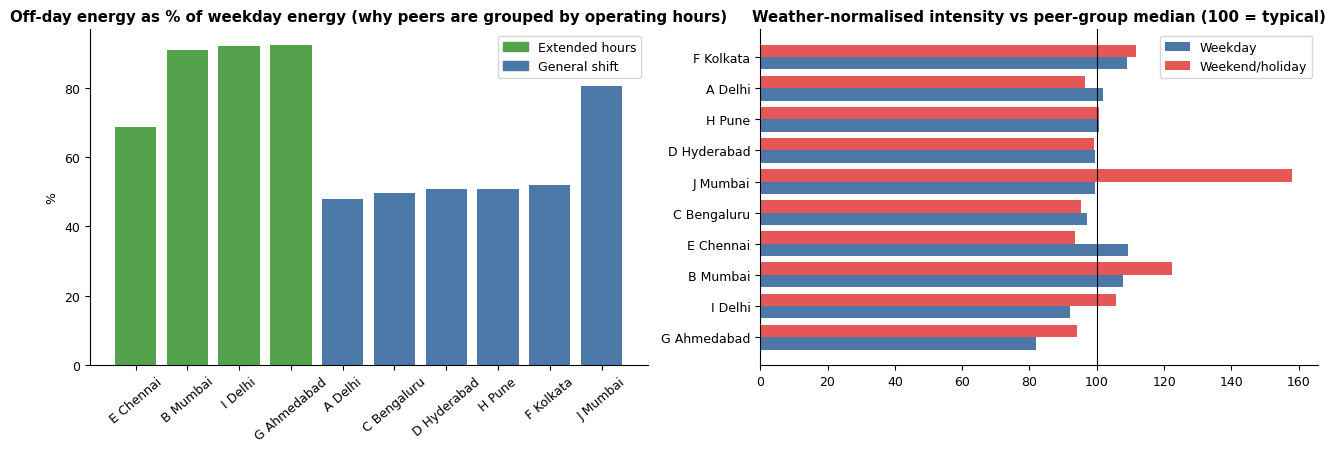

In [15]:
gcol = {"Extended hours": "#54A24B", "General shift": "#4C78A8"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
Q = P.sort_values(["peer_group", "offday_to_weekday_ratio"])
ax[0].bar([lab[i] for i in Q.index], Q.offday_to_weekday_ratio * 100, color=[gcol[g] for g in Q.peer_group])
ax[0].set_title("Off-day energy as % of weekday energy (why peers are grouped by operating hours)"); ax[0].tick_params(axis="x", rotation=40); ax[0].set_ylabel("%")
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in gcol.values()], labels=gcol.keys())
Q = P.sort_values(["peer_group", "weekday_idx_vs_peers"]); y = np.arange(len(Q))
ax[1].barh(y - .2, Q.weekday_idx_vs_peers, .4, color="#4C78A8", label="Weekday"); ax[1].barh(y + .2, Q.offday_idx_vs_peers, .4, color="#E45756", label="Weekend/holiday")
ax[1].set_yticks(y); ax[1].set_yticklabels([f"{lab[i]}" for i in Q.index]); ax[1].axvline(100, color="k", lw=.8)
ax[1].set_title("Weather-normalised intensity vs peer-group median (100 = typical)"); ax[1].legend(); plt.tight_layout(); plt.show()



### Chart 2: actual vs expected for four sites
Red is actual, dashed blue is expected. The model learned from April to June (left of the dotted line). C Bengaluru and B Mumbai pull away from expectation. D Hyderabad and J Mumbai stay on it.

(The last point on each line is a partial week, so ignore small end-of-chart jumps.)

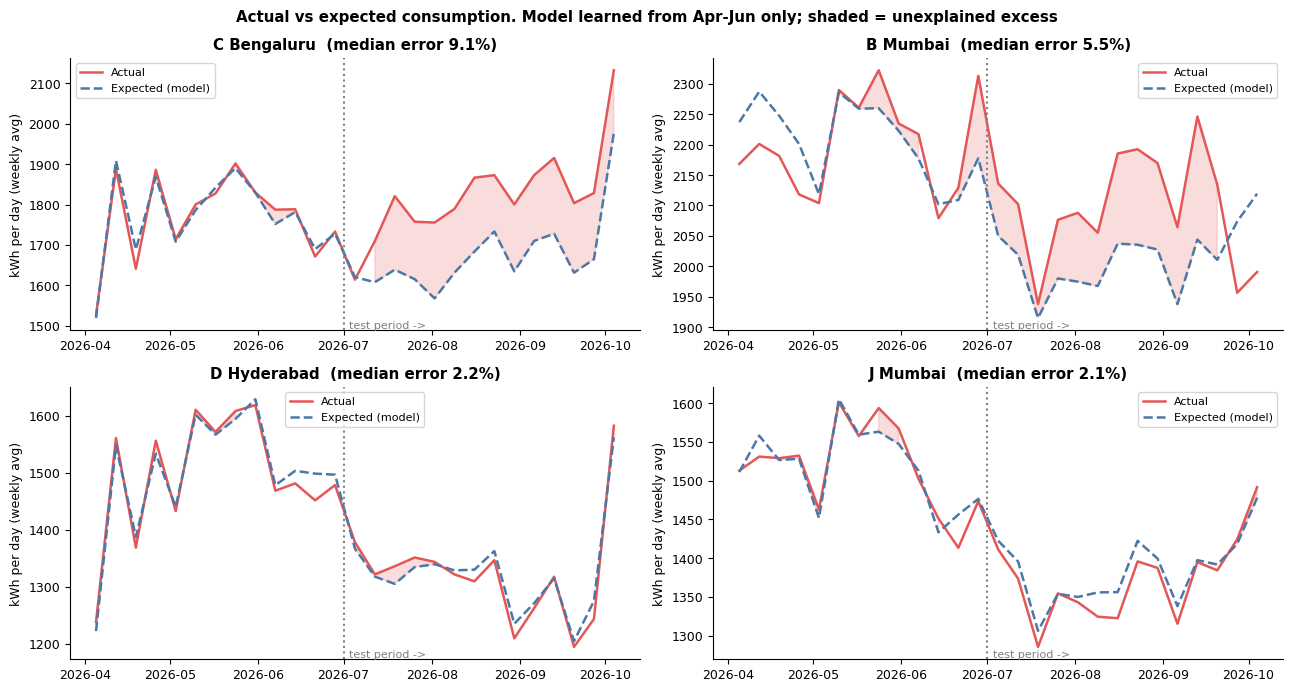

In [16]:
fig, axs = plt.subplots(2, 2, figsize=(13, 7))
for a, s in zip(axs.ravel(), ["S03", "S02", "S04", "S10"]):
    d = df[df.site_id == s].set_index("date")[["total_consumption_kwh", "expected_kwh"]].resample("W").mean()
    a.plot(d.index, d.total_consumption_kwh, color="#E45756", lw=1.8, label="Actual"); a.plot(d.index, d.expected_kwh, color="#4C78A8", lw=1.8, ls="--", label="Expected (model)")
    a.fill_between(d.index, d.expected_kwh, d.total_consumption_kwh, where=d.total_consumption_kwh > d.expected_kwh, color="#E45756", alpha=.2)
    a.axvline(pd.Timestamp("2026-07-01"), color="grey", ls=":"); a.text(pd.Timestamp("2026-07-03"), a.get_ylim()[0], "test period ->", fontsize=8, color="grey", va="bottom")
    a.set_title(f"{lab[s]}  (median error {M.loc[s, 'test_median_abs_pct_err']}%)"); a.legend(fontsize=8); a.set_ylabel("kWh per day (weekly avg)")
plt.suptitle("Actual vs expected consumption. Model learned from Apr-Jun only; shaded = unexplained excess", fontweight="bold"); plt.tight_layout(); plt.show()



### Chart 3: heatmap of weekly excess for all sites
Red means above expected, blue means below. Persistent red rows are the sites to investigate.

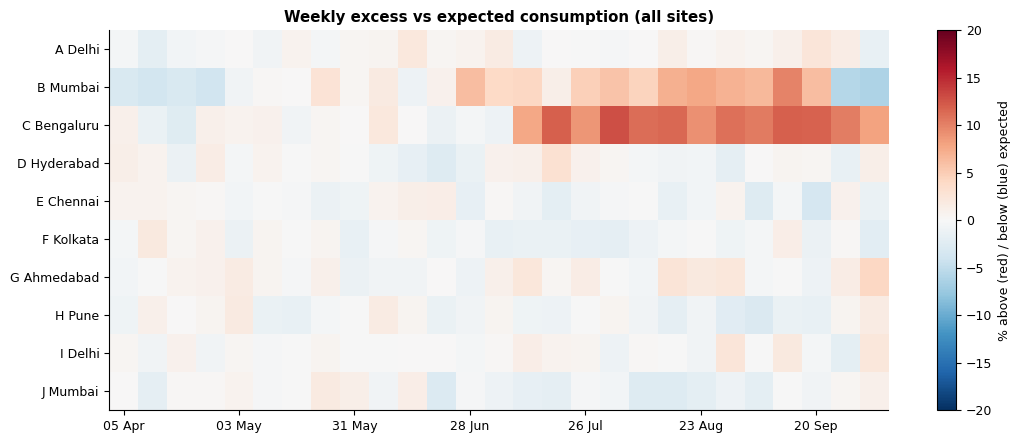

In [17]:
hm = df.set_index("date").groupby("site_id").excess_pct.resample("W").mean().unstack(0)
fig, ax = plt.subplots(figsize=(11, 4.5)); im = ax.imshow(hm.T.values, aspect="auto", cmap="RdBu_r", vmin=-20, vmax=20)
ax.set_yticks(range(len(hm.columns))); ax.set_yticklabels([lab[c] for c in hm.columns]); ax.set_xticks(range(0, len(hm), 4)); ax.set_xticklabels([d.strftime("%d %b") for d in hm.index[::4]])
plt.colorbar(im, label="% above (red) / below (blue) expected"); ax.set_title("Weekly excess vs expected consumption (all sites)")
plt.tight_layout(); plt.show()


## Summary
- **Done:** built fair comparison groups and a weather-adjusted expected-energy model for each site.
- **Found:** C Bengaluru runs about 9% above expectation, B Mumbai about 4%, and the other sites sit within normal noise. J Mumbai looks fine against itself but is far above its peers at weekends.
- **File produced for the next step:** `results/daily_expected_vs_actual.csv`.
- **Next:** Part 3 turns these gaps into formal alerts and explains each one.

# Part 3: Anomaly detection and explanations

**Goal:** turn "expected vs actual" gaps into a clear list of **alerts**, each with a start date, a cost in ₹ and tCO₂e, a plain-English explanation, and any related maintenance ticket.


### How `alerts_with_explanations.csv` is produced, step by step
1. Take the daily gap between actual and expected energy (from Part 2).
2. Run **independent checks**: a rolling z-score, CUSUM, night-load, water, diesel-vs-outage, solar-vs-peers, data quality, weekend-vs-peers, and waste.
3. Each check finds **episodes** (runs of flagged days) and records the onset, end, size of the problem and what it cost.
4. Cost in ₹ = extra kWh × tariff (or litres × diesel price, kL × water cost). tCO₂e = kWh × grid factor, or litres × diesel factor.
5. For each alert we add an explanation and look up related maintenance tickets.
6. Everything is combined into one table and saved to CSV.
7. Finally, the alerts are scored against the answer key (`detection_scorecard.csv`).

### Plain-language glossary
- **z-score:** how many "normal wobbles" away from expected a value is. Around 0 is normal, above 2 or 3 is unusual.
- **Rolling average:** the average of the last N days. One odd day is noise, two weeks of it is a problem.
- **CUSUM:** a running tally that adds up evidence of being above expected and never goes below zero. Random noise cancels out, a small steady problem keeps adding up until it crosses an alarm level. It is good at slow drifts.
- **Episode:** a run of flagged days grouped into one alert.

## Load the data

In [18]:
"""
PHASE 6: Anomaly detection (residual z-score, CUSUM, domain rule checks, peer comparison)
PHASE 7: Explainability (exact additive decomposition + night/day split + maintenance-ticket linking)
Inputs : the SQL view results and the expected-vs-actual table from Part 2.
"""
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt

OUT = "results/"
df = pd.read_csv("sql/results/vw_daily_clean.csv", parse_dates=["date"])
res = daily_expected.copy()
df = df.merge(res[["site_id", "date", "expected_kwh", "excess_kwh", "excess_pct", "excess_z"]], on=["site_id", "date"])
df = df.sort_values(["site_id", "date"]).reset_index(drop=True)
site = pd.read_csv("data/dim_site.csv").set_index("site_id")
tk = pd.read_csv("data/fact_maintenance_tickets.csv", parse_dates=["date_opened", "date_closed"])
wk = pd.read_csv("sql/results/vw_waste_kpi.csv")
fw = pd.read_csv("data/fact_waste_monthly.csv")
peer = P.copy()
ref = dict(pd.read_csv("data/dim_reference_factors.csv")[["factor_name", "value"]].values)
GEF, DEF, DPRICE, WPRICE = ref["grid_emission_factor"], ref["diesel_emission_factor"], ref["diesel_price"], ref["water_tariff_assumed"]
lab = {i: site.loc[i, "site_name"].replace("Site ", "").replace(" - ", " ") for i in site.index}
TEST = pd.Timestamp("2026-07-01"); D = pd.Timedelta(days=1)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
ols = lambda X, y: np.linalg.lstsq(X, y, rcond=None)[0]



## Helper: group flagged days into episodes
Turns a list of flagged days (like 3 July, 4 July, 5 July, 8 July) into one alert with a start, an end and a count. Small gaps are tolerated.

In [19]:
# ------------------------------------------------------------------ helper: group flagged days into episodes
def episodes(flag, dates, min_days=3, max_gap=3):
    idx = np.flatnonzero(flag.values); out = []
    if len(idx) == 0: return out
    runs, st, pv = [], idx[0], idx[0]
    for i in idx[1:]:
        if i - pv > max_gap + 1: runs.append((st, pv)); st = i
        pv = i
    runs.append((st, pv))
    for a, b in runs:
        fl = np.flatnonzero(flag.values[a:b + 1]) + a
        if len(fl) >= min_days: out.append((dates.iloc[a], dates.iloc[b], len(fl), dates.iloc[fl[min_days - 1]]))
    return out



## Extra baselines: night load and water
Same idea as the energy model in Part 2. Night-time load is predicted from CDD and day type. Water is predicted from headcount, CDD and rain. Both are trained on April to June clean days. The percentage gap between actual and predicted is later used to detect problems.

We also compute rolling averages, the solar yield compared with peer solar sites in the same month and rain condition (weather cancels out), and the gap between generator hours and grid outage hours.

In [20]:
# ------------------------------------------------------------------ extra baselines: night load and water (trained Apr-Jun, clean days)
df["night_exp"] = np.nan; df["water_exp"] = np.nan; coefE = {}
Xn = lambda x: np.c_[np.ones(len(x)), x.cdd_base22c, x.is_off_day]
Xw = lambda x: np.c_[np.ones(len(x)), x.headcount, x.cdd_base22c, (x.rainfall_mm > 0).astype(int)]
Xe = lambda x: np.c_[np.ones(len(x)), x.cdd_base22c, x.headcount, x.is_off_day, x.cdd_base22c * x.is_off_day]
for s, d in df.groupby("site_id"):
    tr = d[(d.date < TEST) & (d.dq_flag == "OK")]
    df.loc[d.index, "night_exp"] = Xn(d) @ ols(Xn(tr), tr.night_baseload_kwh)
    df.loc[d.index, "water_exp"] = Xw(d) @ ols(Xw(tr), tr.water_kl)
    coefE[s] = ols(Xe(tr), tr.total_consumption_kwh)
df["night_res_pct"] = (df.night_baseload_kwh - df.night_exp) / df.night_exp * 100
df["water_res_pct"] = (df.water_kl - df.water_exp) / df.water_exp * 100
g = df.groupby("site_id")
df["night_r7"] = g.night_res_pct.transform(lambda x: x.rolling(7, min_periods=7).mean())
df["water_r7"] = g.water_res_pct.transform(lambda x: x.rolling(7, min_periods=7).mean())
df["z_r14"] = g.excess_z.transform(lambda x: x.rolling(14, min_periods=14).mean())
df["dg_gap"] = df.dg_runtime_hrs - df.grid_outage_hrs
# solar yield relative to same-month, same-rain-status peers (weather cancels out)
df["solar_yield"] = df.solar_kwh / df.solar_capacity_kwp
sol = df[df.solar_capacity_kwp > 0].copy(); sol["rain"] = (sol.rainfall_mm > 0).astype(int)
refy = sol.groupby(["month_num", "rain"]).solar_yield.median().rename("ref_yield")
sol = sol.join(refy, on=["month_num", "rain"]); sol["solar_ratio"] = sol.solar_yield / sol.ref_yield
sol["ratio_r5"] = sol.groupby("site_id").solar_ratio.transform(lambda x: x.rolling(5, min_periods=5).median())
df = df.merge(sol[["site_id", "date", "ref_yield", "solar_ratio", "ratio_r5"]], on=["site_id", "date"], how="left")



## Alert list and cost calculator
`add()` records one alert and converts it to rupees and tCO₂e (kWh × tariff, litres × diesel price, kL × water cost, and the emission factors).

In [21]:
alerts = []
def add(site_id, check, start, end, nflag, alarm, metric, kwh=0.0, litres=0.0, kl=0.0, kg=0.0, extra=None):
    t = site.loc[site_id, "grid_tariff_inr_per_kwh"]
    cost = kwh * t + litres * DPRICE + kl * WPRICE
    tco2 = kwh / 1000 * GEF + litres * DEF / 1000
    alerts.append(dict(site_id=site_id, site=lab[site_id], check=check, onset=start, end=end, days_flagged=nflag, alarm_date=alarm, metric=metric,
                       excess_kwh=round(kwh, 0), excess_diesel_l=round(litres, 0), excess_water_kl=round(kl, 1), excess_waste_kg=round(kg, 0),
                       est_cost_inr=round(cost, 0), est_tco2e=round(tco2, 2), **(extra or {})))


**Onset estimate:** a rolling average only fires several days after a problem starts, so `backdate()` looks back to the last quiet day to estimate when it really began.

In [22]:
def backdate(d, alarm, win, col, low):
    """Onset = day after the last 'quiet' day (3-day mean below `low`) in the look-back window."""
    m3 = d[col].rolling(3, min_periods=3).mean()
    below = d.loc[(d.date <= alarm) & (d.date > alarm - win * D) & (m3 < low), "date"]
    return (below.max() + D) if len(below) else (alarm - (win - 1) * D)



## Setting alarm levels from normal noise
**CUSUM alarm level:** instead of using a textbook number, we simulate the site's normal noise (from April to June) thousands of times and set the alarm level so a false alarm would be rare. This does not use the answer key.

**Night and water thresholds:** four times the normal noise of each site, and never below 10%.

In [23]:
# --- calibrate CUSUM alarm level H from the training-period noise (block bootstrap, 97.5th percentile of max CUSUM over a 92-day run)
rng = np.random.default_rng(0)
trz = {x: df[(df.site_id == x) & (df.date < TEST) & (df.dq_flag == "OK")].excess_z.values for x in site.index}
mx = []
for _ in range(2000):
    z = trz[rng.choice(list(trz))]; path = []
    while len(path) < 92:
        a0 = rng.integers(0, len(z) - 7); path.extend(z[a0:a0 + 7])
    S_, m_ = 0.0, 0.0
    for x in path[:92]: S_ = max(0.0, S_ + x - 0.5); m_ = max(m_, S_)
    mx.append(m_)
H = float(np.percentile(mx, 97.5)); print(f"CUSUM alarm level H calibrated from training noise = {H:.1f}")


CUSUM alarm level H calibrated from training noise = 7.2


In [24]:
# --- noise-calibrated thresholds for night-load and water residuals (4 x training noise, never below 10%)
thr = {}
for x in site.index:
    t_ = df[(df.site_id == x) & (df.date < TEST) & (df.dq_flag == "OK")]
    thr[x] = (max(10.0, 4 * t_.night_r7.std()), max(10.0, 4 * t_.water_r7.std()))
print("night/water thresholds (%):", {lab[k]: (round(v[0], 1), round(v[1], 1)) for k, v in thr.items()})



night/water thresholds (%): {'A Delhi': (10.0, 10.0), 'B Mumbai': (np.float64(11.6), 10.0), 'C Bengaluru': (10.0, 10.0), 'D Hyderabad': (10.0, 10.0), 'E Chennai': (10.0, 10.0), 'F Kolkata': (10.0, 10.0), 'G Ahmedabad': (10.0, 10.0), 'H Pune': (10.0, np.float64(10.2)), 'I Delhi': (10.0, 10.0), 'J Mumbai': (10.0, 10.0)}


## Detector 1: sustained excess (rolling z-score)
Takes the 14-day average of the standardised gap between actual and expected energy. If it stays above 1, that site is using more than it should.

In [25]:
for s, d in df.groupby("site_id"):
    d = d.reset_index(drop=True); tst = d[d.date >= TEST].reset_index(drop=True)
    # (1) rolling-z : 14-day average of standardised residual > 1.0
    for st, en, n, al in episodes(tst.z_r14 > 1.0, tst.date, min_days=3, max_gap=3):
        on = backdate(d, st, 14, "excess_z", 0.5); dd = d[(d.date >= on) & (d.date <= en)]
        add(s, "energy_vs_expected", on, en, n, st, f"{dd.excess_kwh.sum() / dd.expected_kwh.sum() * 100:+.1f}% vs expected", kwh=dd.excess_kwh.sum())


## Detector 2: slow drift (CUSUM)
Keeps a running tally of the gap above a small allowance (0.5). When the tally crosses the alarm level, a drift is flagged. This is the method that catches gradual problems like a chiller slowly getting less efficient.

In [26]:
cusum, cusum_alarm = {}, {}
for s, d in df.groupby("site_id"):
    d = d.reset_index(drop=True); tst = d[d.date >= TEST].reset_index(drop=True)
    # (2) CUSUM : running tally of standardised residuals, slack k=0.5, alarm when tally > H
    S, path, first = 0.0, [], None
    for dt, z in zip(tst.date, tst.excess_z):
        S = max(0.0, S + z - 0.5); path.append(S)
        if first is None and S > H: first = dt
    cusum[s] = pd.Series(path, index=tst.date); cusum_alarm[s] = first
    if first is not None:
        cs = cusum[s]; zero = cs[(cs.index < first) & (cs == 0)].index; on = (zero.max() + D) if len(zero) else tst.date.iloc[0]
        en = cs[cs > H].index.max(); dd = d[(d.date >= on) & (d.date <= en)]
        add(s, "drift_cusum", on, en, int((cs > H).sum()), first, f"{dd.excess_kwh.sum() / dd.expected_kwh.sum() * 100:+.1f}% vs expected (CUSUM)", kwh=dd.excess_kwh.sum())


## Detector 3: night-time load vs expected
Flags a site when its 12am to 5am consumption is well above what it should be for the weather and day type.

In [27]:
for s, d in df.groupby("site_id"):
    d = d.reset_index(drop=True); tst = d[d.date >= TEST].reset_index(drop=True)
    # (3) night baseload vs expected
    for st, en, n, al in episodes(tst.night_r7 > thr[s][0], tst.date, min_days=3, max_gap=3):
        on = backdate(d, st, 7, "night_res_pct", 7.5); dd = d[(d.date >= on) & (d.date <= en)]
        add(s, "night_baseload_vs_expected", on, en, n, st, f"{dd.night_res_pct.mean():+.0f}% night load", kwh=(dd.night_baseload_kwh - dd.night_exp).sum())


## Detector 4: water vs expected
Flags a site when its water use is well above what headcount, heat and rain explain, for example a leak.

In [28]:
for s, d in df.groupby("site_id"):
    d = d.reset_index(drop=True); tst = d[d.date >= TEST].reset_index(drop=True)
    # (4) water vs expected
    for st, en, n, al in episodes(tst.water_r7 > thr[s][1], tst.date, min_days=3, max_gap=3):
        on = backdate(d, st, 7, "water_res_pct", 7.5); dd = d[(d.date >= on) & (d.date <= en)]
        add(s, "water_vs_expected", on, en, n, st, f"{dd.water_res_pct.mean():+.0f}% water", kl=(dd.water_kl - dd.water_exp).sum())


## Detector 5: diesel generator vs grid outages
If the generator ran more than an hour longer than the utility log shows the grid was off, that is flagged. The extra diesel is estimated from the unexplained hours.

In [29]:
for s, d in df.groupby("site_id"):
    d = d.reset_index(drop=True); tst = d[d.date >= TEST].reset_index(drop=True)
    # (5) DG running with grid healthy (full period, rule needs no training)
    for st, en, n, al in episodes(d.dg_gap > 1.0, d.date, min_days=3, max_gap=3):
        dd = d[(d.date >= st) & (d.date <= en) & (d.dg_gap > 1.0)]
        lit = (dd.dg_diesel_litres * dd.dg_gap / dd.dg_runtime_hrs).sum()
        add(s, "dg_vs_outage", st, en, n, al, f"{dd.dg_gap.sum():.0f} DG hrs with no outage", litres=lit)


## Detector 6: solar yield vs peer solar sites
Solar output per kW is compared with the other solar sites in the same month and rain condition. A site well below its peers for several days is flagged.

In [30]:
for s, d in df.groupby("site_id"):
    d = d.reset_index(drop=True); tst = d[d.date >= TEST].reset_index(drop=True)
    # (6) solar yield vs peers
    if d.solar_capacity_kwp.iloc[0] > 0:
        for st, en, n, al in episodes(d.ratio_r5 < 0.8, d.date, min_days=3, max_gap=2):
            dd = d[(d.date >= st) & (d.date <= en)]
            lost = ((dd.ref_yield - dd.solar_yield).clip(lower=0) * dd.solar_capacity_kwp).sum()
            add(s, "solar_yield_vs_peers", st, en, n, al, f"yield {dd.solar_ratio.mean() * 100:.0f}% of peers", kwh=lost)


## Detector 7: data quality
Missing or absurdly large grid readings are flagged so they can be fixed at the source before any report.

In [31]:
for s, d in df.groupby("site_id"):
    d = d.reset_index(drop=True); tst = d[d.date >= TEST].reset_index(drop=True)
    # (7) data quality
    for st, en, n, al in episodes(d.dq_flag != "OK", d.date, min_days=1, max_gap=0):
        dd = d[(d.date >= st) & (d.date <= en)]
        add(s, "data_quality", st, en, n, al, ",".join(sorted(dd.dq_flag.unique())) + f" grid_kwh ({n} d)")


## Detector 8: weekend and holiday use vs peers
Uses the peer comparison from Part 2. A site using far more energy than its peers when people are away is flagged.

In [32]:
# (8) peer check: weekend/holiday intensity vs peer-group median
n_off = df[df.site_id == "S01"].is_off_day.sum()
for s, r in peer.iterrows():
    if r.offday_idx_vs_peers > 130:
        med = peer[peer.peer_group == r.peer_group].std_offday_kwh_sqm.median()
        ex = (r.std_offday_kwh_sqm - med) * site.loc[s, "floor_area_sqm"] * n_off
        add(s, "offday_vs_peers", df.date.min(), df.date.max(), int(n_off), pd.NaT, f"off-day intensity {r.offday_idx_vs_peers:.0f}% of peers", kwh=ex)



## Detector 9: waste vs peers (monthly)
Flags low recycling rates, high wet/food waste per person, and one-off building waste, each compared with the other waste-tracked sites in the same month.

In [33]:
# (9) waste vs peers (monthly)
wk["month_start"] = pd.to_datetime(wk.month_id.astype(str) + "01", format="%Y%m%d"); fwm = fw.set_index(["site_id", "month_id"])
pdays = df.assign(m=df.date.dt.year * 100 + df.date.dt.month).groupby(["site_id", "m"]).headcount.sum()
nz = fw.building_waste_kg[fw.building_waste_kg > 0].median()
for s, w in wk.groupby("site_id"):
    w = w.sort_values("month_id").reset_index(drop=True); rows = []
    for _, r in w.iterrows():
        o = wk[(wk.month_id == r.month_id) & (wk.site_id != s)]
        rows.append(dict(rec=r.recycling_rate_pct < 0.6 * o.recycling_rate_pct.median(), wet=r.wet_waste_kg_per_head_day > 1.5 * o.wet_waste_kg_per_head_day.median(),
                         bld=fwm.loc[(s, r.month_id), "building_waste_kg"] > 3 * nz,
                         short=(o.recycling_rate_pct.median() - r.recycling_rate_pct) / 100 * r.recyclable_kg,
                         wetx=(r.wet_waste_kg_per_head_day - o.wet_waste_kg_per_head_day.median()) * pdays.loc[(s, r.month_id)],
                         bldkg=fwm.loc[(s, r.month_id), "building_waste_kg"]))
    R = pd.DataFrame(rows)
    for col, check, label_, kgcol in [("rec", "waste_recycling", "recycling rate far below peers", "short"), ("wet", "waste_wet_per_head", "wet waste/head far above peers", "wetx"),
                                      ("bld", "waste_building_oneoff", "one-off building waste", "bldkg")]:
        for st, en, n, al in episodes(R[col], w.month_start, min_days=1, max_gap=0):
            m = (w.month_start >= st) & (w.month_start <= en) & R[col]
            add(s, check, st, en + pd.offsets.MonthEnd(0), n, en + pd.offsets.MonthEnd(0), f"{label_} ({n} mo)", kg=R.loc[m, kgcol].clip(lower=0).sum())


## All alerts so far
Every detector has added to one list. This puts it into a table.

In [34]:
A = pd.DataFrame(alerts)
print(len(A), 'raw alerts from', A.check.nunique(), 'different checks')
A[['site', 'check', 'onset', 'end', 'metric', 'est_cost_inr']].head(10)

19 raw alerts from 11 different checks


,site,check,onset,end,metric,est_cost_inr
0,B Mumbai,energy_vs_expected,2026-06-23,2026-07-11,+5.0% vs expected,20357.0
1,B Mumbai,energy_vs_expected,2026-07-29,2026-09-23,+6.3% vs expected,73390.0
2,C Bengaluru,energy_vs_expected,2026-07-09,2026-09-30,+10.1% vs expected,118522.0
3,B Mumbai,drift_cusum,2026-07-01,2026-09-30,+4.4% vs expected (CUSUM),83398.0
4,C Bengaluru,drift_cusum,2026-07-08,2026-09-30,+10.0% vs expected (CUSUM),118897.0
5,B Mumbai,night_baseload_vs_expected,2026-09-16,2026-09-18,+14% night load,1528.0
6,C Bengaluru,night_baseload_vs_expected,2026-07-10,2026-09-30,+55% night load,97013.0
7,F Kolkata,water_vs_expected,2026-08-02,2026-09-30,+113% water,12362.0
8,H Pune,water_vs_expected,2026-07-04,2026-07-25,+13% water,308.0
9,H Pune,water_vs_expected,2026-08-01,2026-08-28,+17% water,528.0


## Phase 7: Explaining each alert
**Why:** an alert saying "Site C is abnormal" is not actionable. We add the reason.

**Driver breakdown:** because our baseline is a simple formula, we can split the change in daily consumption exactly into **weather**, **occupancy**, **calendar** and **unexplained**. The unexplained part is the problem.

In [35]:
def decomp(s, a, b):
    d = df[df.site_id == s]; tr = d[(d.date < TEST) & (d.dq_flag == "OK")]; w = d[(d.date >= a) & (d.date <= b)]; be = coefE[s]
    dx = Xe(w).mean(0) - Xe(tr).mean(0)
    return dict(baseline=tr.total_consumption_kwh.mean(), weather=be[1] * dx[1] + be[4] * dx[4], occupancy=be[2] * dx[2], calendar=be[3] * dx[3],
                unexplained=(w.total_consumption_kwh - Xe(w) @ be).mean(), actual=w.total_consumption_kwh.mean())


**Explanation text and ticket linking:** for each alert we check what share of the excess falls at night (to tell out-of-hours load from all-day inefficiency), confirm headcount did not change, and find maintenance tickets at the same site near the alert dates.

*Note: ticket linking is a simple date and category match, so treat it as a suggestion, not a proof.*

In [36]:
expl, decs = [], {}
for i, a in A.iterrows():
    d = df[(df.site_id == a.site_id) & (df.date >= a.onset) & (df.date <= a.end)]; txt = ""
    if a.check in ("energy_vs_expected", "drift_cusum"):
        dc = decomp(a.site_id, a.onset, a.end); decs[a.site_id] = dc if (a.site_id not in decs or a.check == "drift_cusum") else decs[a.site_id]
        nres = (d.night_baseload_kwh - d.night_exp).sum(); share = nres / d.excess_kwh.sum() if d.excess_kwh.sum() > 0 else np.nan
        nshare = d.night_baseload_kwh.sum() / d.total_consumption_kwh.sum()
        hc = (d.headcount.mean() / df[(df.site_id == a.site_id) & (df.date < TEST)].headcount.mean() - 1) * 100
        kind = "out-of-hours load (check BMS/AHU schedules and overrides)" if share > 0.5 and share > 2 * nshare else "spread across the day (check plant efficiency: chiller, condenser, filters)"
        txt = (f"{a.metric}; weather effect {dc['weather']:+.0f} kWh/day and occupancy effect {dc['occupancy']:+.0f} kWh/day are already in the expectation (headcount {hc:+.0f}% vs baseline), "
               f"leaving {dc['unexplained']:+.0f} kWh/day unexplained. {share * 100:.0f}% of the excess falls between 12am-5am, which is only {nshare * 100:.0f}% of normal demand -> {kind}.")
    elif a.check == "night_baseload_vs_expected": txt = f"{a.metric} while headcount and weather are normal -> equipment running when the building should be idle."
    elif a.check == "dg_vs_outage": txt = f"{a.metric}; generator ran while the utility log shows the grid healthy -> possible peak-shaving or test-run misuse. Diesel wasted about {a.excess_diesel_l:.0f} L."
    elif a.check == "solar_yield_vs_peers": txt = f"{a.metric} on the same-month, same-weather basis -> inverter/soiling/string fault suspected. About {a.excess_kwh:.0f} kWh lost."
    elif a.check == "water_vs_expected": txt = f"{a.metric} with headcount and weather already accounted for -> suspect leak or valve/float fault. About {a.excess_water_kl:.0f} kL extra."
    elif a.check == "offday_vs_peers": txt = f"{a.metric} although people are away -> no setback of HVAC/lighting on weekends and holidays."
    elif a.check == "data_quality": txt = f"{a.metric} -> fix the source reading before reporting; values were gap-filled/excluded."
    else: txt = a.metric
    # maintenance-ticket link
    cats = {"energy_vs_expected": ["HVAC", "BMS", "Electrical", "Lighting"], "drift_cusum": ["HVAC", "BMS", "Electrical", "Lighting"], "night_baseload_vs_expected": ["HVAC", "BMS", "Electrical", "Lighting"], "dg_vs_outage": ["DG", "Electrical"],
            "solar_yield_vs_peers": ["Solar", "Electrical"], "water_vs_expected": ["Plumbing"], "offday_vs_peers": ["BMS", "HVAC"]}.get(a.check, [])
    t = tk[(tk.site_id == a.site_id) & tk.asset_category.isin(cats) & (tk.date_opened >= a.onset - 45 * D) & (tk.date_opened <= a.end + 30 * D)] if cats else tk.iloc[0:0]
    if cats and len(t):
        t = t.iloc[(t.date_opened - a.onset).abs().argsort()]; t1 = t.iloc[0]
        lagtxt = (t1.date_opened - a.onset).days if a.check != "offday_vs_peers" else np.nan
        tix = " | ".join(f"{r.ticket_id} ({r.asset_category}: {r.description}; opened {r.date_opened.date()}; {r.status})" for r in t.head(2).itertuples())
    else: tix, lagtxt = ("no related ticket found" if cats else ""), np.nan
    expl.append(dict(explanation=txt, related_tickets=tix, ticket_lag_days_after_onset=lagtxt))


## Final alerts table
Explanations and ticket links are attached, alerts are sorted by estimated cost, given IDs and saved. **This is where `alerts_with_explanations.csv` is created.**

In [37]:
A = pd.concat([A, pd.DataFrame(expl)], axis=1)
A["issue_family"] = A.check.map({"energy_vs_expected": "energy demand", "drift_cusum": "energy demand", "night_baseload_vs_expected": "energy demand", "offday_vs_peers": "weekend setback", "dg_vs_outage": "diesel", "solar_yield_vs_peers": "solar", "water_vs_expected": "water", "data_quality": "data quality"}).fillna("waste")
A = A.sort_values(["est_cost_inr", "site_id", "onset"], ascending=[False, True, True]).reset_index(drop=True)
A.insert(0, "alert_id", [f"AL{n:03d}" for n in range(1, len(A) + 1)])
A.to_csv(OUT + "alerts_with_explanations.csv", index=False)
print("Driver breakdown, kWh per day:\n", pd.DataFrame(decs).T.round(0).to_string())


A[['alert_id', 'site', 'check', 'onset', 'metric', 'est_cost_inr', 'est_tco2e']].head(15)

Driver breakdown, kWh per day:
      baseline  weather  occupancy  calendar  unexplained  actual
S02    2205.0   -194.0       -8.0       3.0         89.0  2095.0
S03    1778.0   -138.0       11.0       9.0        167.0  1826.0


,alert_id,site,check,onset,metric,est_cost_inr,est_tco2e
0,AL001,J Mumbai,offday_vs_peers,2026-04-01,off-day intensity 158% of peers,274519.0,19.57
1,AL002,H Pune,dg_vs_outage,2026-06-01,82 DG hrs with no outage,162795.0,4.85
2,AL003,C Bengaluru,drift_cusum,2026-07-08,+10.0% vs expected (CUSUM),118897.0,10.29
3,AL004,C Bengaluru,energy_vs_expected,2026-07-09,+10.1% vs expected,118522.0,10.26
4,AL005,C Bengaluru,night_baseload_vs_expected,2026-07-10,+55% night load,97013.0,8.40
5,AL006,B Mumbai,drift_cusum,2026-07-01,+4.4% vs expected (CUSUM),83398.0,5.94
6,AL007,B Mumbai,energy_vs_expected,2026-07-29,+6.3% vs expected,73390.0,5.23
7,AL008,A Delhi,solar_yield_vs_peers,2026-08-17,yield 49% of peers,28311.0,2.31
8,AL009,B Mumbai,energy_vs_expected,2026-06-23,+5.0% vs expected,20357.0,1.45
9,AL010,F Kolkata,water_vs_expected,2026-08-02,+113% water,12362.0,0.00


## Scoring against the answer key
The synthetic data had 10 deliberately planted problems. **Only now** do we open the answer key and check what was found and how fast. **This is where `detection_scorecard.csv` is created.**

Remember the caveats: monthly data limits waste alerts to monthly speed, and a gradual problem that starts inside the training window (B Mumbai) is only recognised once monitoring starts.

In [38]:
key = pd.read_csv("data/ANSWER_KEY_planted_anomalies.csv", parse_dates=["start", "end"])
mp = {"A01": {"night_baseload_vs_expected", "energy_vs_expected", "drift_cusum"}, "A02": {"energy_vs_expected", "drift_cusum"}, "A03": {"dg_vs_outage"}, "A04": {"solar_yield_vs_peers"},
      "A05": {"water_vs_expected"}, "A06": {"offday_vs_peers"}, "A07": {"data_quality"}, "A08": {"data_quality"}, "A09": {"waste_recycling", "waste_wet_per_head"}, "A10": {"waste_building_oneoff"}}
rows = []
for _, k in key.iterrows():
    m = A[(A.site_id == k.site_id) & A.check.isin(mp[k.anomaly_id]) & (A.onset <= k.end) & (A.end >= k.start)]
    if k.anomaly_id == "A07": m = m[m.metric.str.contains("MISSING")]
    if k.anomaly_id == "A08": m = m[m.metric.str.contains("OUTLIER")]
    cs = cusum_alarm.get(k.site_id) if k.anomaly_id in ("A01", "A02") else None
    first = m.alarm_date.min() if len(m) and m.alarm_date.notna().any() else pd.NaT
    rows.append(dict(anomaly=k.anomaly_id, site=lab[k.site_id], type=k.type, planted_start=k.start.date(), detected=bool(len(m)), checks=",".join(sorted(m.check.unique())),
                     first_alarm=first.date() if pd.notna(first) else "", delay_days=(first - k.start).days if pd.notna(first) else np.nan,
                     cusum_first_alarm=cs.date() if cs is not None and pd.notna(cs) else "", window_days=(k.end - k.start).days + 1))
SC = pd.DataFrame(rows); SC.to_csv(OUT + "detection_scorecard.csv", index=False)


**False alarms:** alerts that match no planted problem. A few small ones are expected, and they cost very little.

In [39]:
matched = set()
for _, k in key.iterrows():
    for i, a in A.iterrows():
        if a.site_id == k.site_id and a.check in mp[k.anomaly_id] and a.onset <= k.end and a.end >= k.start: matched.add(i)
FP = A[~A.index.isin(matched)]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)
print("\nSCORECARD:\n", SC.to_string())
print("\nALERTS NOT MATCHING ANY PLANTED ANOMALY (potential false positives):\n", FP[["site", "check", "onset", "end", "metric", "est_cost_inr"]].to_string() if len(FP) else "none")
print("\nCUSUM first alarms:", {lab[k]: (v.date() if pd.notna(v) else None) for k, v in cusum_alarm.items()})
print("\nALERTS (top):\n", A[["alert_id", "site", "check", "onset", "alarm_date", "metric", "est_cost_inr", "est_tco2e", "related_tickets", "ticket_lag_days_after_onset"]].to_string())
print("\nDECOMPOSITION:\n", pd.DataFrame(decs).T.round(0))
for s_ in ("S03", "S02"):
    x_ = A[(A.site_id == s_) & A.check.isin(["energy_vs_expected", "drift_cusum"])]
    if len(x_): print(lab[s_], "->", x_.explanation.iloc[0])




SCORECARD:


   anomaly         site                             type planted_start  detected                                                     checks first_alarm  delay_days cusum_first_alarm  window_days
0     A01  C Bengaluru       Night baseload step change    2026-07-10      True  drift_cusum,energy_vs_expected,night_baseload_vs_expected  2026-07-10         0.0        2026-07-10           83
1     A02     B Mumbai         Gradual efficiency drift    2026-04-01      True                             drift_cusum,energy_vs_expected  2026-07-02        92.0        2026-07-31          172
2     A03       H Pune        DG used with grid healthy    2026-06-01      True                                               dg_vs_outage  2026-06-03         2.0                             30
3     A04      A Delhi           Solar underperformance    2026-08-15      True                                       solar_yield_vs_peers  2026-08-19         4.0                             22
4     A05    F Kolkata       

## Charts
### CUSUM paths
A tally that stays low is normal. A tally that climbs above the red dashed line is a drift alarm.

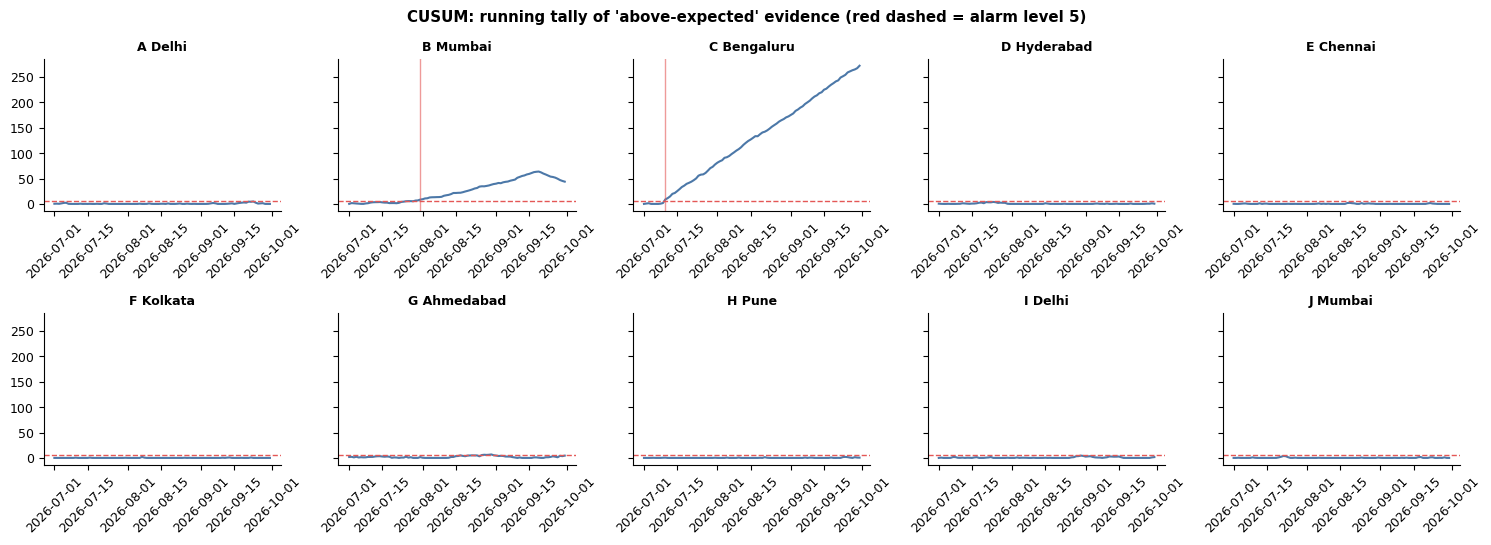

In [40]:
fig, axs = plt.subplots(2, 5, figsize=(15, 5.5), sharey=True)
for a, s in zip(axs.ravel(), site.index):
    a.plot(cusum[s].index, cusum[s].values, color="#4C78A8"); a.axhline(5, color="#E45756", ls="--", lw=1)
    if pd.notna(cusum_alarm[s]): a.axvline(cusum_alarm[s], color="#E45756", lw=1, alpha=.6)
    a.set_title(lab[s], fontsize=9); a.tick_params(axis="x", rotation=45)
fig.suptitle("CUSUM: running tally of 'above-expected' evidence (red dashed = alarm level 5)", fontweight="bold"); plt.tight_layout(); plt.show()



### The rule checks in action
Generator vs outages (H Pune), solar vs peers (A Delhi), water (F Kolkata) and night load (C Bengaluru).

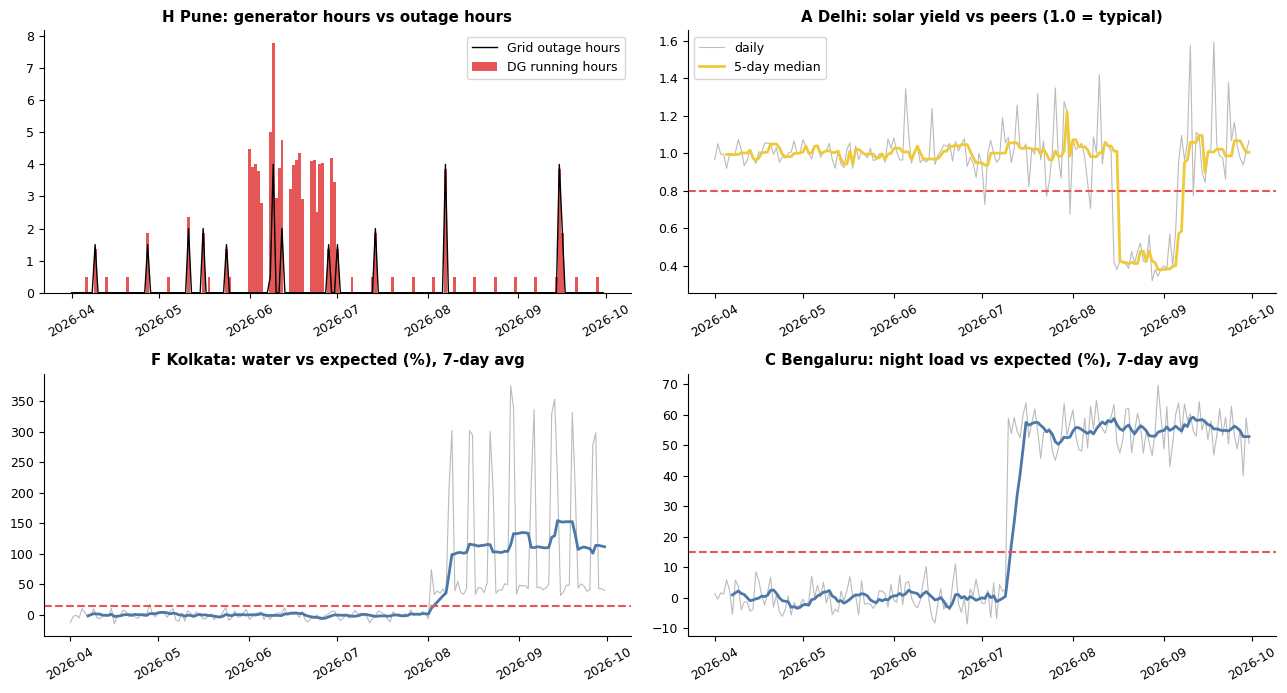

In [41]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
d = df[df.site_id == "S08"]; ax[0, 0].bar(d.date, d.dg_runtime_hrs, color="#E45756", width=1, label="DG running hours"); ax[0, 0].plot(d.date, d.grid_outage_hrs, color="k", lw=1, label="Grid outage hours"); ax[0, 0].set_title("H Pune: generator hours vs outage hours"); ax[0, 0].legend()
d = df[df.site_id == "S01"]; ax[0, 1].plot(d.date, d.solar_ratio, color="#bbb", lw=.8, label="daily"); ax[0, 1].plot(d.date, d.ratio_r5, color="#EECA3B", lw=2, label="5-day median"); ax[0, 1].axhline(.8, color="#E45756", ls="--"); ax[0, 1].set_title("A Delhi: solar yield vs peers (1.0 = typical)"); ax[0, 1].legend()
d = df[df.site_id == "S06"]; ax[1, 0].plot(d.date, d.water_res_pct, color="#bbb", lw=.8); ax[1, 0].plot(d.date, d.water_r7, color="#4C78A8", lw=2); ax[1, 0].axhline(15, color="#E45756", ls="--"); ax[1, 0].set_title("F Kolkata: water vs expected (%), 7-day avg")
d = df[df.site_id == "S03"]; ax[1, 1].plot(d.date, d.night_res_pct, color="#bbb", lw=.8); ax[1, 1].plot(d.date, d.night_r7, color="#4C78A8", lw=2); ax[1, 1].axhline(15, color="#E45756", ls="--"); ax[1, 1].set_title("C Bengaluru: night load vs expected (%), 7-day avg")
for a in ax.ravel(): a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()



### Driver breakdown for C Bengaluru and B Mumbai
Starts from the April to June average, adds the weather effect, occupancy effect, calendar effect and what remains unexplained, ending at actual consumption. (The vertical axis is truncated for readability.)

For C Bengaluru the cooler monsoon should have reduced energy, yet raw consumption barely changed. Adjusted for weather, the building is using about 10% more than it should.

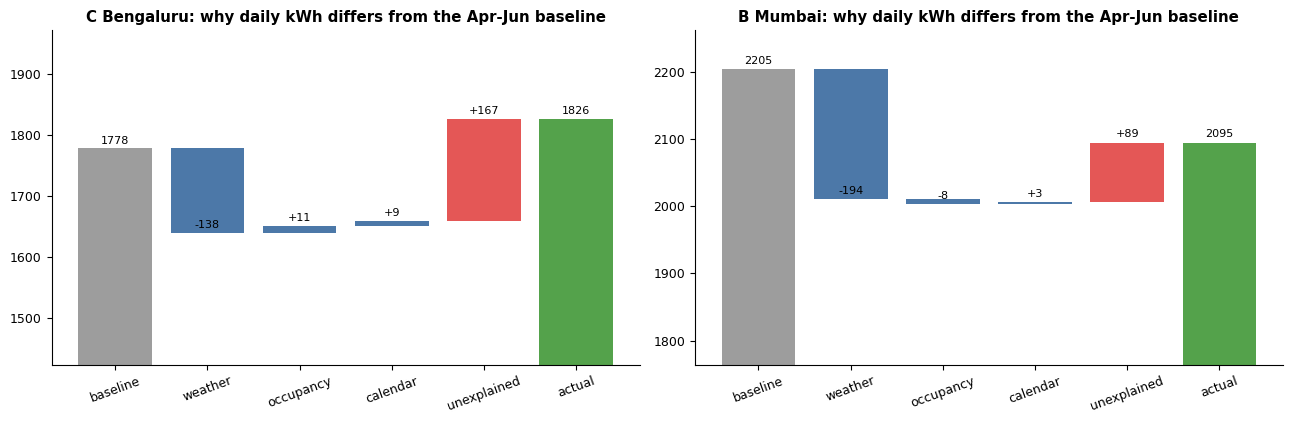

In [42]:
keys = [k for k in ("S03", "S02") if k in decs]
if keys:
    fig, axs = plt.subplots(1, len(keys), figsize=(6.5 * len(keys), 4.3))
    axs = np.atleast_1d(axs)
    for a, s in zip(axs, keys):
        dc = decs[s]; steps = ["baseline", "weather", "occupancy", "calendar", "unexplained"]; cum = 0; 
        for i, n in enumerate(steps):
            v = dc[n]; a.bar(i, v if i else v, bottom=0 if i == 0 else cum, color="#9D9D9D" if i == 0 else ("#E45756" if n == "unexplained" else "#4C78A8")); cum = v if i == 0 else cum + v
            a.text(i, (v if i == 0 else cum) + 8, f"{v:+.0f}" if i else f"{v:.0f}", ha="center", fontsize=8)
        a.bar(5, dc["actual"], color="#54A24B"); a.text(5, dc["actual"] + 8, f"{dc['actual']:.0f}", ha="center", fontsize=8)
        a.set_xticks(range(6)); a.set_xticklabels(steps + ["actual"], rotation=20); a.set_ylim(dc["baseline"] * 0.8, max(dc["actual"], cum) * 1.08); a.set_title(f"{lab[s]}: why daily kWh differs from the Apr-Jun baseline")
    plt.tight_layout(); plt.show()


## Summary
- **Done:** nine checks turned gaps into alerts with cost, emissions, explanation and ticket links.
- **Files produced:** `alerts_with_explanations.csv` (the main result) and `detection_scorecard.csv`.
- **Honest notes:** thresholds are judgment calls validated here only against synthetic data. The CUSUM alarm level was recalibrated from training noise after a first run with a textbook value gave a false alarm. Several alerts describe the same issue (for example C Bengaluru), so costs should not be added up naively.
- **Next (Phase 8):** merge duplicate alerts per issue and build the ranked priority list.

# Part 4: From alerts to a ranked priority list

**Goal:** turn the 19 raw alerts into a short list a facility manager can act on, ranked by money, carbon and urgency.


### The four problems Phase 8 solves
1. **Double counting.** One real problem often triggers several detectors (Site C Bengaluru raised three alerts). Adding them up overstates the money.
2. **Noise.** A few alerts are tiny and short, and are probably random wobble.
3. **Not everything is money.** Waste and data-quality alerts have no rupee value, so they must not be forced into a rupee ranking.
4. **"Which first?"** A manager needs one ordered list, with the reasoning visible.

### The method in plain words
- **Merge:** alerts at the same site, of the same type, that overlap or sit within 7 days of each other are one issue.
- **Measure once:** for energy issues we re-measure the excess directly over the merged window. For others we take the biggest member, not the sum.
- **Label:** each issue gets a status (ongoing or stopped) and a confidence level.
- **Score:** a transparent weighted score, then a sensitivity test to see if the ranking depends on the weights.

## Load the data
The alerts from Part 3, the daily expected-vs-actual table from Part 2, and the portfolio totals.

In [43]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 70)
OUT = "results/"; os.makedirs(OUT, exist_ok=True)

alerts = A.copy()
daily = daily_expected.copy()
site   = pd.read_csv("data/dim_site.csv").set_index("site_id")
ref    = dict(pd.read_csv("data/dim_reference_factors.csv")[["factor_name", "value"]].values)
kpi    = pd.read_csv("sql/results/vw_site_kpi.csv")

GEF  = ref["grid_emission_factor"]          # tCO2 per MWh
LAST = daily.date.max()                     # last day of data
lab  = {i: site.loc[i, "site_name"].replace("Site ", "").replace(" - ", " ") for i in site.index}
print(len(alerts), "alerts loaded")
print("If you simply added up every alert: Rs", f"{alerts.est_cost_inr.sum():,.0f}", "and", round(alerts.est_tco2e.sum(), 1), "tCO2e (this double-counts, see below)")

19 alerts loaded
If you simply added up every alert: Rs 992,020 and 68.4 tCO2e (this double-counts, see below)


## Step 1: Merge duplicate alerts into issues
**What we do:** sort alerts by site and issue type, then walk through them in date order. If the next alert starts within 7 days of the current issue's end, it belongs to the same issue. Otherwise it begins a new one. Waste alerts are kept apart by check, because low recycling and a wet-waste spike are different problems.

In [44]:
GAP = pd.Timedelta(days=7)          # alerts closer than 7 days apart are treated as the same episode
alerts = alerts.sort_values(["site_id", "issue_family", "check", "onset"]).reset_index(drop=True)
alerts["group_key"] = np.where(alerts.issue_family == "waste", alerts.site_id + "|" + alerts.check, alerts.site_id + "|" + alerts.issue_family)
alerts = alerts.sort_values(["group_key", "onset"]).reset_index(drop=True)

issue_no, cid, prev = [], 0, None
for _, r in alerts.iterrows():
    if r.group_key != prev:                       # new site/issue type -> new issue
        cid += 1; cur_end = r.end; prev = r.group_key
    elif r.onset > cur_end + GAP:                 # same type but far apart in time -> a separate issue
        cid += 1; cur_end = r.end
    else:                                         # overlapping or close -> same issue
        cur_end = max(cur_end, r.end)
    issue_no.append(cid)
alerts["issue_no"] = issue_no
print(len(alerts), "alerts became", alerts.issue_no.nunique(), "distinct issues")
alerts[["issue_no", "site", "check", "onset", "end", "est_cost_inr"]].sort_values(["issue_no", "onset"]).head(12)

19 alerts became 13 distinct issues


,issue_no,site,check,onset,end,est_cost_inr
0,1,A Delhi,solar_yield_vs_peers,2026-08-17,2026-09-07,28311.0
1,2,B Mumbai,energy_vs_expected,2026-06-23,2026-07-11,20357.0
2,2,B Mumbai,drift_cusum,2026-07-01,2026-09-30,83398.0
3,2,B Mumbai,energy_vs_expected,2026-07-29,2026-09-23,73390.0
4,2,B Mumbai,night_baseload_vs_expected,2026-09-16,2026-09-18,1528.0
5,3,C Bengaluru,drift_cusum,2026-07-08,2026-09-30,118897.0
6,3,C Bengaluru,energy_vs_expected,2026-07-09,2026-09-30,118522.0
7,3,C Bengaluru,night_baseload_vs_expected,2026-07-10,2026-09-30,97013.0
8,4,C Bengaluru,waste_building_oneoff,2026-07-01,2026-07-31,0.0
9,5,D Hyderabad,data_quality,2026-06-12,2026-06-16,0.0


## Step 2: Build one row per issue
**What we do:** for each issue we record the first onset, the last end, how many alerts and detectors were involved, and the impact.

**Avoiding double counting:** for *energy* issues we re-add the daily excess directly from the Part 2 table over the whole window, instead of adding alert totals. For diesel, solar, water and the weekend check we take the largest member alert. Compare `naive_cost_inr` (the old sum) with `cost_inr` (merged).

In [45]:
rows = []
for n, g in alerts.groupby("issue_no"):
    best = g.loc[g.est_cost_inr.idxmax()] if g.est_cost_inr.max() > 0 else g.iloc[0]     # the member with the biggest impact
    s, fam, on, en = g.site_id.iloc[0], g.issue_family.iloc[0], g.onset.min(), g.end.max()
    if fam == "energy demand":
        # re-measure the excess directly over the whole merged window (avoids double counting)
        w = daily[(daily.site_id == s) & (daily.date >= on) & (daily.date <= en)]
        kwh, cost = w.excess_kwh.sum(), w.excess_inr.sum(); tco2 = kwh / 1000 * GEF; litres = kl = kg = 0
    else:
        kwh, litres, kl, kg, cost, tco2 = best.excess_kwh, best.excess_diesel_l, best.excess_water_kl, best.excess_waste_kg, best.est_cost_inr, best.est_tco2e
    rows.append(dict(site_id=s, site=lab[s], issue_family=fam, onset=on, end=en, n_alerts=len(g), detectors=", ".join(sorted(g.check.unique())), n_detectors=g.check.nunique(),
                     days_flagged=int(g.days_flagged.max()), naive_cost_inr=g.est_cost_inr.sum(), cost_inr=round(cost), tco2e=round(tco2, 2), excess_kwh=round(kwh),
                     diesel_l=litres, water_kl=kl, waste_kg=kg, what_happened=best.metric, explanation=best.explanation, related_tickets=best.related_tickets))
I = pd.DataFrame(rows)
I[["site", "issue_family", "onset", "end", "n_alerts", "naive_cost_inr", "cost_inr", "tco2e"]]

,site,issue_family,onset,end,n_alerts,naive_cost_inr,cost_inr,tco2e
0,A Delhi,solar,2026-08-17,2026-09-07,1,28311.0,28311,2.31
1,B Mumbai,energy demand,2026-06-23,2026-09-30,4,178673.0,95672,6.82
2,C Bengaluru,energy demand,2026-07-08,2026-09-30,3,334432.0,118897,10.29
3,C Bengaluru,waste,2026-07-01,2026-07-31,1,0.0,0,0.00
4,D Hyderabad,data quality,2026-06-12,2026-06-16,1,0.0,0,0.00
5,D Hyderabad,data quality,2026-07-22,2026-07-22,1,0.0,0,0.00
6,E Chennai,waste,2026-04-01,2026-09-30,1,0.0,0,0.00
7,E Chennai,waste,2026-08-01,2026-08-31,1,0.0,0,0.00
8,F Kolkata,water,2026-08-02,2026-09-30,1,12362.0,12362,0.00
9,H Pune,diesel,2026-06-01,2026-06-30,1,162795.0,162795,4.85


## Step 3: Status and confidence
**Ongoing or stopped?** For energy issues, are the last 14 days still above expectation? Standing behaviours (weekend setback) are always ongoing. Others are ongoing if the alert reaches the end of the data.

**Confidence:**
- *High*: two or more independent detectors agree, or a direct log reconciliation (diesel hours vs outage hours).
- *Medium*: one detector, sustained for at least 5 days.
- *Low*: fewer than 5 days flagged.

**Run-rate:** monthly cost = cost to date ÷ months the issue lasted. We only project forward (×12) for ongoing issues, because a stopped problem is no longer losing money.

In [46]:
def active_now(r):
    """Is the problem still happening at the end of the data?"""
    if r.issue_family == "energy demand":        # still above expectation over the last 14 days?
        z = daily[(daily.site_id == r.site_id) & (daily.date > LAST - pd.Timedelta(days=14))].excess_z.mean()
        return bool(z > 1.0)
    if r.detectors == "offday_vs_peers": return True          # a standing behaviour, not an event
    return bool(r.end >= LAST - pd.Timedelta(days=7))

def confidence(r):
    if r.days_flagged < 5: return "Low"                                              # too short to trust
    if r.n_detectors >= 2 or r.detectors == "dg_vs_outage": return "High"          # independent detectors agree, or a direct log reconciliation
    return "Medium"                                                                  # one detector, sustained

I["active_now"] = I.apply(active_now, axis=1)
I["confidence"] = I.apply(confidence, axis=1)
span_days = (I.end - I.onset).dt.days + 1
I["monthly_cost_inr"] = I.cost_inr / (span_days / 30.4)
I["annual_if_unfixed_inr"] = np.where(I.active_now, I.monthly_cost_inr * 12, 0).round(-3)   # only ongoing issues keep costing money
I[["site", "issue_family", "active_now", "confidence", "cost_inr", "annual_if_unfixed_inr"]]

,site,issue_family,active_now,confidence,cost_inr,annual_if_unfixed_inr
0,A Delhi,solar,False,Medium,28311,0.0
1,B Mumbai,energy demand,False,High,95672,0.0
2,C Bengaluru,energy demand,True,High,118897,510000.0
3,C Bengaluru,waste,False,Low,0,0.0
4,D Hyderabad,data quality,False,Medium,0,0.0
5,D Hyderabad,data quality,False,Low,0,0.0
6,E Chennai,waste,True,Medium,0,0.0
7,E Chennai,waste,False,Low,0,0.0
8,F Kolkata,water,True,Medium,12362,75000.0
9,H Pune,diesel,False,High,162795,0.0


## Step 4: Split into the right lists
- **Priority list:** energy, weekend, diesel, solar and water issues with a rupee impact of at least ₹5,000 over six months. The materiality limit is a judgment call, so state it.
- **Data-quality fixes:** fix the source reading, no ranking needed.
- **Waste watch-list:** measured in kg, not rupees, so kept separate (and a good ESG talking point).
- **Below materiality:** small issues recorded but not prioritised.

In [47]:
MATERIAL = 5000      # ignore money issues below Rs 5,000 over six months
money = I[I.issue_family.isin(["energy demand", "weekend setback", "diesel", "solar", "water"])]
priority    = money[money.cost_inr >= MATERIAL].copy()
immaterial  = money[money.cost_inr <  MATERIAL].copy()
dq_fixes    = I[I.issue_family == "data quality"].copy()
waste_watch = I[I.issue_family == "waste"].copy()
print("Priority list:", len(priority), "| below materiality:", len(immaterial), "| data-quality fixes:", len(dq_fixes), "| waste watch-list:", len(waste_watch))

Priority list: 6 | below materiality: 2 | data-quality fixes: 2 | waste watch-list: 3


## Step 5: Priority score
Each priority issue gets a score out of 100:

`score = 100 × (0.5 × money + 0.2 × carbon + 0.2 × ongoing + 0.1 × confidence)`

where *money* and *carbon* are the issue's share of the largest one, *ongoing* is 1 or 0, and *confidence* is 1 / 0.6 / 0.2 for High / Medium / Low.

**These weights are my judgment**, not a standard. That is why the next step tests whether the order changes if you change them.

In [48]:
CONF = {"High": 1.0, "Medium": 0.6, "Low": 0.2}
W = dict(money=0.5, carbon=0.2, active=0.2, confidence=0.1)

def score(df, w):
    return 100 * (w["money"] * df.cost_inr / df.cost_inr.max()
                + w["carbon"] * df.tco2e / df.tco2e.max()
                + w["active"] * df.active_now.astype(float)
                + w["confidence"] * df.confidence.map(CONF))

priority["priority_score"] = score(priority, W).round(1)
priority = priority.sort_values("priority_score", ascending=False).reset_index(drop=True)
priority.insert(0, "rank", range(1, len(priority) + 1))
priority["status"] = np.where(priority.active_now, "Ongoing", "Stopped/resolved")
ACTION = {"energy demand": "Inspect BMS/AHU schedules and overrides, then plant efficiency (chiller, condenser)",
          "weekend setback": "Set weekend/holiday setback for HVAC and lighting in the BMS",
          "diesel": "Audit the DG run log, stop peak-shaving runs, verify ATS settings",
          "solar": "Inspect inverters, strings and panel cleaning; set a yield alert",
          "water": "Look for leaks: night flow, pump room, tanks and valves"}
priority["first_action"] = priority.issue_family.map(ACTION)
priority[["rank", "site", "issue_family", "status", "confidence", "cost_inr", "tco2e", "annual_if_unfixed_inr", "priority_score"]]

,rank,site,issue_family,status,confidence,cost_inr,tco2e,annual_if_unfixed_inr,priority_score
0,1,J Mumbai,weekend setback,Ongoing,Medium,274519,19.57,547000.0,96.0
1,2,C Bengaluru,energy demand,Ongoing,High,118897,10.29,510000.0,62.2
2,3,H Pune,diesel,Stopped/resolved,High,162795,4.85,0.0,44.6
3,4,B Mumbai,energy demand,Stopped/resolved,High,95672,6.82,0.0,34.4
4,5,F Kolkata,water,Ongoing,Medium,12362,0.00,75000.0,28.3
5,6,A Delhi,solar,Stopped/resolved,Medium,28311,2.31,0.0,13.5


## Step 6: Does the ranking depend on the weights?
We re-rank under four different weightings. If the same issues stay near the top, the conclusion is solid. Where the order moves, that is where judgment matters.

In [49]:
SCEN = {"Default (money 50, carbon 20, ongoing 20, conf 10)": W,
        "Money only": dict(money=1, carbon=0, active=0, confidence=0),
        "Carbon-heavy": dict(money=.3, carbon=.5, active=.1, confidence=.1),
        "Urgency-heavy (ongoing first)": dict(money=.3, carbon=.1, active=.5, confidence=.1)}
sens = pd.DataFrame({k: score(priority, w).rank(ascending=False, method="min").astype(int) for k, w in SCEN.items()})
sens.index = priority.site + " | " + priority.issue_family
sens

,"Default (money 50, carbon 20, ongoing 20, conf 10)",Money only,Carbon-heavy,Urgency-heavy (ongoing first)
J Mumbai | weekend setback,1,1,1,1
C Bengaluru | energy demand,2,3,2,2
H Pune | diesel,3,2,3,4
B Mumbai | energy demand,4,4,4,5
F Kolkata | water,5,6,5,3
A Delhi | solar,6,5,6,6


## Step 7: Save the results
This is where `priority_list.csv` is created (the other lists are only printed below).

In [50]:
cols = ["rank", "site_id", "site", "issue_family", "status", "confidence", "onset", "end", "cost_inr", "tco2e", "excess_kwh", "diesel_l", "water_kl",
        "annual_if_unfixed_inr", "priority_score", "first_action", "what_happened", "explanation", "related_tickets", "detectors", "n_alerts", "naive_cost_inr"]
priority[cols].to_csv(OUT + "priority_list.csv", index=False)
print("\n--- Data-quality fixes ---"); print(dq_fixes[["site", "onset", "end", "what_happened"]].to_string(index=False))
print("\n--- Waste watch-list ---"); print(waste_watch[["site", "detectors", "onset", "end", "waste_kg", "what_happened"]].to_string(index=False))
print("\n--- Below materiality (likely noise) ---"); print(immaterial[["site", "issue_family", "onset", "end", "cost_inr", "what_happened"]].to_string(index=False))


--- Data-quality fixes ---
       site      onset        end          what_happened
D Hyderabad 2026-06-12 2026-06-16 MISSING grid_kwh (5 d)
D Hyderabad 2026-07-22 2026-07-22 OUTLIER grid_kwh (1 d)

--- Waste watch-list ---
       site             detectors      onset        end  waste_kg                         what_happened
C Bengaluru waste_building_oneoff 2026-07-01 2026-07-31    1250.0         one-off building waste (1 mo)
  E Chennai       waste_recycling 2026-04-01 2026-09-30    1456.0 recycling rate far below peers (6 mo)
  E Chennai    waste_wet_per_head 2026-08-01 2026-08-31    1480.0 wet waste/head far above peers (1 mo)

--- Below materiality (likely noise) ---
  site issue_family      onset        end  cost_inr what_happened
H Pune        water 2026-07-04 2026-08-28       528    +17% water
H Pune        water 2026-09-12 2026-09-18        92    +15% water


## Step 8: Headline numbers
The totals after merging, put against the whole portfolio so the scale is clear.

In [51]:
port_cost = kpi.utility_cost_lakh_inr.sum() * 1e5
port_co2  = kpi.total_tco2e.sum()
naive     = alerts.est_cost_inr.sum()
merged    = priority.cost_inr.sum()
ongoing   = priority[priority.active_now]
print(f"Adding up all 19 alerts naively: Rs {naive:,.0f}")
print(f"After merging duplicates and dropping immaterial noise: Rs {merged:,.0f} across {len(priority)} issues")
print(f"   = {merged / port_cost * 100:.1f}% of the portfolio's six-month utility cost (Rs {port_cost:,.0f})")
print(f"   = {priority.tco2e.sum():.1f} tCO2e, {priority.tco2e.sum() / port_co2 * 100:.1f}% of portfolio emissions ({port_co2:,.0f} tCO2e)")
print(f"Still ongoing: {len(ongoing)} issues. If left unfixed they cost about Rs {ongoing.annual_if_unfixed_inr.sum():,.0f} per year")

Adding up all 19 alerts naively: Rs 992,020
After merging duplicates and dropping immaterial noise: Rs 692,556 across 6 issues
   = 2.0% of the portfolio's six-month utility cost (Rs 34,049,000)
   = 43.8 tCO2e, 1.7% of portfolio emissions (2,621 tCO2e)
Still ongoing: 3 issues. If left unfixed they cost about Rs 1,132,000 per year


## Chart 1: the ranked issues

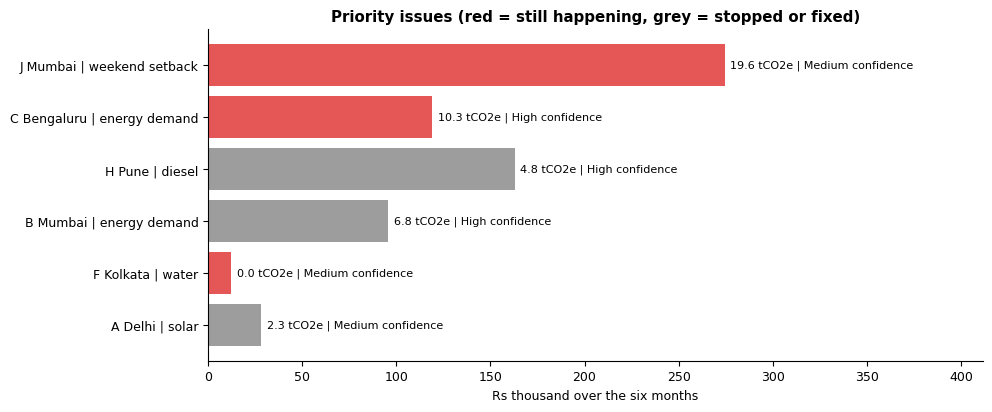

In [52]:
fig, ax = plt.subplots(figsize=(10, 4.2))
p = priority.iloc[::-1]
bars = ax.barh(p.site + " | " + p.issue_family, p.cost_inr / 1000, color=np.where(p.active_now, "#E45756", "#9D9D9D"))
for y, (c, t, cf) in enumerate(zip(p.cost_inr / 1000, p.tco2e, p.confidence)): ax.text(c + 3, y, f"{t:.1f} tCO2e | {cf} confidence", va="center", fontsize=8)
ax.set_xlabel("Rs thousand over the six months"); ax.set_xlim(0, p.cost_inr.max() / 1000 * 1.5)
ax.set_title("Priority issues (red = still happening, grey = stopped or fixed)")
plt.tight_layout(); plt.show()

## Chart 2: why merging mattered
Sites where several detectors described one problem look much worse if you add the alerts up.

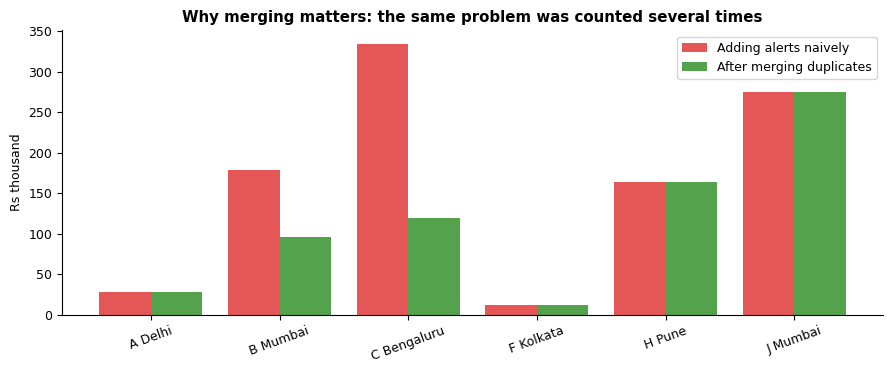

In [53]:
g = I[I.issue_family.isin(["energy demand", "weekend setback", "diesel", "solar", "water"])].groupby("site").agg(naive=("naive_cost_inr", "sum"), merged=("cost_inr", "sum"))
g = g[g.naive > 0]
fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(len(g))
ax.bar(x - .2, g.naive / 1000, .4, color="#E45756", label="Adding alerts naively"); ax.bar(x + .2, g.merged / 1000, .4, color="#54A24B", label="After merging duplicates")
ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=20); ax.set_ylabel("Rs thousand"); ax.legend(); ax.set_title("Why merging matters: the same problem was counted several times")
plt.tight_layout(); plt.show()

## Summary
- **Done:** 19 raw alerts were merged into 13 distinct issues. Six of them have a rupee impact above the ₹5,000 materiality limit and form the **priority list**. The rest went to a data-quality list, a waste watch-list, and a "below materiality" list.
- **Ranking (default weights):** 1 J Mumbai weekend setback, 2 C Bengaluru energy demand, 3 H Pune diesel (stopped), 4 B Mumbai energy demand (stopped), 5 F Kolkata water, 6 A Delhi solar (stopped).
- **Scale:** after removing double counting, the priority issues come to about ₹6.9 lakh and 43.8 tCO₂e over six months. That is about 2.0% of the portfolio's utility cost and 1.7% of its emissions. Adding the alerts up naively would have given ₹9.9 lakh.
- **Still ongoing:** three issues (J Mumbai, C Bengaluru, F Kolkata). If left unfixed they would cost about ₹11.3 lakh per year.
- **Does the order depend on the weights?** J Mumbai is first under all four weightings and C Bengaluru stays second or third. The middle of the list moves (H Pune is 2nd to 4th, F Kolkata is 3rd to 6th), so treat ranks 3 to 6 as a group, not a strict order.

**Honest caveats**
- The top-ranked J Mumbai figure is a **gap against peers**, which is a benchmark and not a measured change, so its confidence is Medium. If the peer median is the wrong yardstick for that building, the number shrinks.
- The score weights and the ₹5,000 limit are judgment calls. The sensitivity test shows how much they matter.
- Annual figures assume the current rate continues, which is a projection, not a forecast.
- Water is not converted to carbon here, so the F Kolkata leak scores low on the carbon part even though it wastes a resource.
- This is synthetic data with planted problems, so the numbers show the method working, not real savings.

**Main result:** `results/priority_list.csv`, the final ranked list.


# What this analysis produced
- `results/alerts_with_explanations.csv`: every alert with its cost, explanation and related ticket.
- `results/detection_scorecard.csv`: how many of the 10 planted problems were found, and how fast.
- `results/priority_list.csv`: the final ranked list of issues.

The dashboard (`dashboard.html`) shows these results visually, and `monthly/` repeats the checks on a new month's data.